# CS180 Project 3, Part A: Exploring the Power of Flow Models
Hovhannes Antablyan · CS 180 Fall 2026 · https://codegrox.github.io/cs180_proj3/

Sampling, editing and optical illusions with the pretrained PixNerd-XXL-P16-T2I flow model (512×512, pixel space).
Run on a Colab Tesla T4. The course support files and my 13 input images are restored from Google Drive by the setup
cell; every result is saved to `MyDrive/cs180_proj3_parta_final/img` as a lossless 512×512 PNG and reused on a rerun.
Inline figures are small previews; the full-size results are on the project page.

Contents: required Sections 1.1–3.4 → CS280A bells & whistles (two more anagram transformations, a course logo) →
own ideas (Euler step-count sweep, inpainting and object swapping, 4- and 6-way rotation anagrams, "make it real") →
additional runs from the same session (more hybrid candidates and refinements).

Fixed settings: seed 180, Euler step h = 0.02, CFG w = 7 (Part A convention v_c + w(v_c − v_u)).


In [ ]:
#@title Setup: GPU, course support files and my input images (cached on Google Drive)
import os, sys, time, hashlib, zipfile
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'parta'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True, exist_ok=True)
EXPECTED_SHA256 = '96c4f3d6d116c8a1fb04dbed4dc81bbb4ca3a4b9c334fb407308316010ce5bfc'
SUPPORT_NAME = 'parta_final_support.zip'
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    persistent_assets = Path('/content/drive/MyDrive/cs180_proj3_assets')
    persistent_assets.mkdir(parents=True, exist_ok=True)
    support_path = persistent_assets / SUPPORT_NAME
    if not support_path.is_file():
        print('FIRST RUN ONLY: upload', SUPPORT_NAME, 'from your computer.')
        from google.colab import files
        uploaded = files.upload()
        if SUPPORT_NAME not in uploaded:
            raise FileNotFoundError(f'Please upload {SUPPORT_NAME}, not the whole project ZIP.')
        support_path.write_bytes(uploaded[SUPPORT_NAME])
        print('Support archive saved permanently to your new Google Drive:', support_path)
elif IN_KAGGLE:
    matches = list(Path('/kaggle/input').rglob(SUPPORT_NAME))
    if not matches:
        raise FileNotFoundError('Add parta_final_support.zip as a private Kaggle Dataset input.')
    support_path = matches[0]
else:
    support_path = Path(SUPPORT_NAME)
    if not support_path.exists():
        raise FileNotFoundError(str(support_path))
if hashlib.sha256(support_path.read_bytes()).hexdigest() != EXPECTED_SHA256:
    raise ValueError('Support archive checksum mismatch — please use the matching download.')
with zipfile.ZipFile(support_path) as z:
    assert z.testzip() is None, 'Invalid support archive'
    for item in z.infolist():
        target = (_work / item.filename).resolve()
        if _work.resolve() not in target.parents:
            raise ValueError('Unsafe archive path: ' + item.filename)
    z.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0, str(_work))
from colab_setup import configure
configure(PART, install_dependencies=IN_COLAB or IN_KAGGLE)
print('Ready. Support files and images restored:', len(list(Path('my_inputs').glob('*.png'))), 'custom PNGs.')


Mounted at /content/drive
Installing required packages: transformers==4.51.3, huggingface-hub==0.36.2
GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
Local cache: /content/cs180-hw3/.cache
Part A precision: float32 (text encoder and image model).
Ready. Support files and images restored: 13 custom PNGs.


In [ ]:
#@title Results folder on Google Drive
import os, sys
from pathlib import Path
if 'google.colab' in sys.modules:
    PERSIST = Path('/content/drive/MyDrive')
elif Path('/kaggle/working').is_dir():
    PERSIST = Path('/kaggle/working')
else:
    PERSIST = Path.cwd()
OUT = Path(os.environ.get('CS180_RESULTS', PERSIST / 'cs180_proj3_parta_final'))
(OUT / 'img').mkdir(parents=True, exist_ok=True)
(OUT / 'panels').mkdir(exist_ok=True)
print('Inputs:', sorted(p.name for p in Path('my_inputs').glob('*.png')))
print('Results:', OUT)


Inputs: ['chalk_cliffs.png', 'comet_1881.png', 'fantasy_architecture.png', 'kart_drawing.png', 'logo_cs180.png', 'logo_sketch.png', 'pig_drawing.png', 'pixel_fuji.png', 'pixel_statue.png', 'saturn_1874.png', 'seascape_rain.png', 'vouet_portrait.png', 'wivenhoe_park.png']
Results: /content/drive/MyDrive/cs180_proj3_parta_final


In [ ]:
import json, time, math
import torch, numpy as np, matplotlib.pyplot as plt
import torch.nn.functional as F
ROOT = Path.cwd()
from PIL import Image
from torchvision.transforms.functional import gaussian_blur
from flow_model import FlowModel, preprocess, to_pil, MODEL_ID, MODEL_REVISION
SEED, H, W = 180, 0.02, 7
if 'model' not in globals():
    model = FlowModel()
device = model.device
_calls = {"n": 0}


def predict_velocity(x, t, condition):
    _calls["n"] += 1
    return model.predict_velocity(x, t, condition)


condition = model.encode("a high quality photo")
null_condition = model.encode("")


def noise(seed):
    return torch.randn((1, 3, 512, 512), generator=torch.Generator().manual_seed(seed)).to(device)


def load(name):
    return preprocess(Path('my_inputs') / name).to(device)


def save(name, x):
    to_pil(x).save(OUT / 'img' / (name + '.png'))


def cached(name, fn):
    p = OUT / 'img' / (name + '.png')
    if p.is_file():
        return preprocess(p).to(device)
    x = fn()
    save(name, x)
    return x


_mp = OUT / 'metrics.json'
metrics = json.loads(_mp.read_text()) if _mp.is_file() else {}
metrics.update({"seed": SEED, "step_size": H, "cfg_w": W, "model": MODEL_ID, "revision": MODEL_REVISION,
                "gpu": torch.cuda.get_device_name(0)})
metrics.setdefault("timing", {})


def record(stage, t0, c0):
    torch.cuda.synchronize()
    n = _calls["n"] - c0
    if n:  # keep the timing of the session that actually computed the stage
        s = time.perf_counter() - t0
        metrics["timing"][stage] = {"seconds": round(s, 1), "network_evals": n, "seconds_per_eval": round(s / n, 3)}
    _mp.write_text(json.dumps(metrics, indent=2))
    print(stage, metrics["timing"].get(stage), flush=True)



def show(images, columns=4, title=None):
    """Small inline preview only; the website uses the lossless PNGs in OUT/img."""
    items = list(images.items())
    rows = math.ceil(len(items) / columns)
    fig, axs = plt.subplots(rows, columns, figsize=(2.6 * columns, 2.75 * rows), squeeze=False)
    for ax in axs.flat:
        ax.axis('off')
    for ax, (label, x) in zip(axs.flat, items):
        ax.imshow(to_pil(x) if torch.is_tensor(x) else x)
        ax.set_title(label, fontsize=7, wrap=True)
    if title:
        fig.suptitle(title, fontsize=9)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def img(name):
    return preprocess(OUT / 'img' / (name + '.png')).to(device)


def guided(x, t, c=None, w=None):
    return cfg_velocity(x, t, condition if c is None else c, W if w is None else w, predict_velocity, null_condition)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.ckpt:   0%|          | 0.00/4.70G [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/622M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

In [ ]:
# My implementations of the student functions, used throughout Part A.

def interpolate(image, noise, t):
    """x_t = (1 - t) * eps + t * x_1  (t = 0 is pure noise, t = 1 is the clean image)."""
    return (1 - t) * noise + t * image


def one_step_denoise(x, t, condition, predict_velocity):
    """Jump straight to t = 1 along the predicted velocity: x_1_hat = x_t + (1 - t) v(x_t, t, c)."""
    return x + (1 - t) * predict_velocity(x, t, condition)


@torch.inference_mode()
def euler_sample(x_start, t_start, step_size, velocity):
    """Integrate dx/dt = velocity(x, t) from t_start to exactly 1.

    The number of steps is fixed up front (ceil((1 - t_start) / h)) and each time is computed as
    t_start + k*h, so float round-off can never add an extra tiny step; the last step is shortened
    to land on t = 1. Returns the final state and the saved states [(t, x)]: the initial state,
    every fifth update, and the final state.
    """
    x = x_start.float()
    n = math.ceil(round((1.0 - t_start) / step_size, 9))
    states = [(float(t_start), x.clone())]
    for k in range(n):
        t = t_start + k * step_size
        h = min(step_size, 1.0 - t)
        x = x + h * velocity(x, t)
        t_next = 1.0 if k == n - 1 else t_start + (k + 1) * step_size
        if (k + 1) % 5 == 0 or k == n - 1:
            states.append((float(t_next), x.clone()))
    return x, states


def cfg_velocity(x, t, condition, w, predict_velocity, null_condition=''):
    """Classifier-free guidance: v = v_c + w (v_c - v_u); both branches see the same x and t."""
    v_cond = predict_velocity(x, t, condition)
    if w == 0:
        return v_cond
    v_uncond = predict_velocity(x, t, null_condition)
    return v_cond + w * (v_cond - v_uncond)


def edit(image, noise, t_start, condition, predict_velocity, w=7, step_size=0.02):
    """SDEdit-style editing: noise the image to t_start, then integrate back to t = 1 with CFG."""
    x = interpolate(image, noise, t_start)
    velocity = lambda x, t: cfg_velocity(x, t, condition, w, predict_velocity, null_condition)
    return euler_sample(x, t_start, step_size, velocity)[0]


# Provided by the course: rotate by 180 degrees, keeping the batch and RGB axes unchanged.
def rotate180(x):
    return torch.flip(x, (-2, -1))


def visual_anagrams(noise, condition_a, condition_b, predict_velocity, w=7, step_size=0.02):
    """Average the upright velocity for prompt a with the rotated-back velocity for prompt b."""
    def velocity(x, t):
        v_a = cfg_velocity(x, t, condition_a, w, predict_velocity, null_condition)
        v_b = rotate180(cfg_velocity(rotate180(x), t, condition_b, w, predict_velocity, null_condition))
        return (v_a + v_b) / 2
    return euler_sample(noise, 0, step_size, velocity)[0]


# Provided by the course: at 512 x 512 this uses kernel size 265 and sigma 16.
def lowpass(x, sigma=16.0):
    kernel = 2 * round(16.5 * x.shape[-1] / 64) + 1
    return gaussian_blur(x, [kernel, kernel], [sigma, sigma])


def make_hybrids(noise, condition_a, condition_b, predict_velocity, w=7, step_size=0.02):
    """Factorized velocity: low frequencies from prompt a (seen from afar), high from prompt b (seen up close)."""
    def velocity(x, t):
        v_a = cfg_velocity(x, t, condition_a, w, predict_velocity, null_condition)
        v_b = cfg_velocity(x, t, condition_b, w, predict_velocity, null_condition)
        return lowpass(v_a) + (v_b - lowpass(v_b))
    return euler_sample(noise, 0, step_size, velocity)[0]


In [ ]:
@torch.inference_mode()
def velocity_diagnostics(x_t, t, clean_image, epsilon, condition, predict_velocity):
    """Return predicted_update, ground_truth_update, and error_map.

    Both updates have shape (B, 3, H, W).
    The error map has shape (B, H, W): average only over RGB, keeping each pixel.
    Return raw values before display scaling or clipping.
    """
    v_hat = predict_velocity(x_t, t, condition)
    predicted_update = (1 - t) * v_hat
    ground_truth_update = (1 - t) * (clean_image - epsilon)   # == clean_image - x_t
    error_map = ((predicted_update - ground_truth_update) ** 2).mean(dim=1).sqrt()
    return predicted_update, ground_truth_update, error_map


## 1. Visualizing Training and Sampling


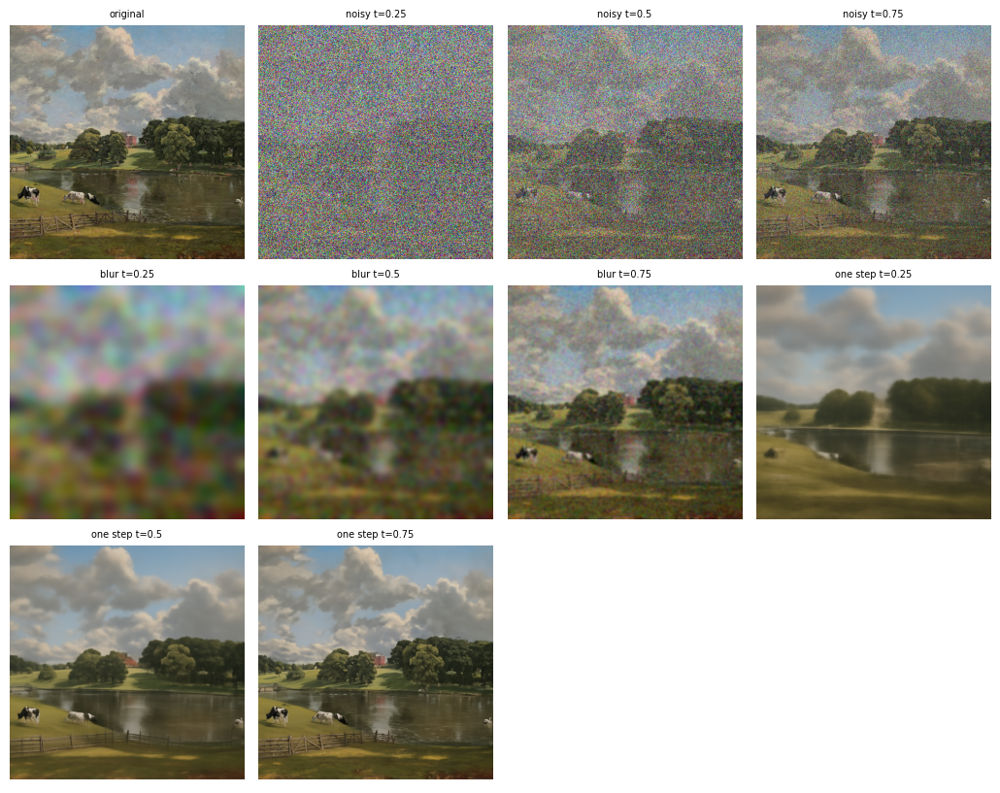

1.1-1.3 {'seconds': 5.1, 'network_evals': 3, 'seconds_per_eval': 1.715}


In [ ]:
# 1.1-1.3: noisy training inputs, Gaussian-blur baseline, one-step denoising (my image: Constable, Wivenhoe Park).
_t0, _c0 = time.perf_counter(), _calls["n"]
image, epsilon = load('wivenhoe_park.png'), noise(SEED)
noisy = {t: interpolate(image, epsilon, t) for t in (0.25, 0.50, 0.75)}
assert torch.equal(interpolate(image, epsilon, 0), epsilon) and torch.equal(interpolate(image, epsilon, 1), image)
save('sec1_original', image)
metrics['sec1'] = {'blur': {}, 'one_step_mse': {}}
SIGMAS = [0.5, 1., 1.5, 2., 3., 4., 6., 8., 12., 16.]
blurred, one_step = {}, {}
for t, x in noisy.items():
    save(f'sec1_noisy_{t:.2f}', x)
    cands = {sg: gaussian_blur(x / t, [2 * math.ceil(3 * sg) + 1] * 2, [sg, sg]) for sg in SIGMAS}
    mse = {sg: float(((v - image) ** 2).mean()) for sg, v in cands.items()}
    best = min(mse, key=mse.get)
    blurred[t] = cands[best]
    save(f'sec1_blur_{t:.2f}', blurred[t])
    metrics['sec1']['blur'][f'{t:.2f}'] = {'best_sigma': best, 'mse': mse}
    one_step[t] = cached(f'sec1_onestep_{t:.2f}', lambda: one_step_denoise(x, t, condition, predict_velocity))
    metrics['sec1']['one_step_mse'][f'{t:.2f}'] = float(((one_step[t] - image) ** 2).mean())
show({'original': image, **{f'noisy t={t}': x for t, x in noisy.items()},
      **{f'blur t={t}': blurred[t] for t in noisy}, **{f'one step t={t}': one_step[t] for t in noisy}}, columns=4)
record('1.1-1.3', _t0, _c0)


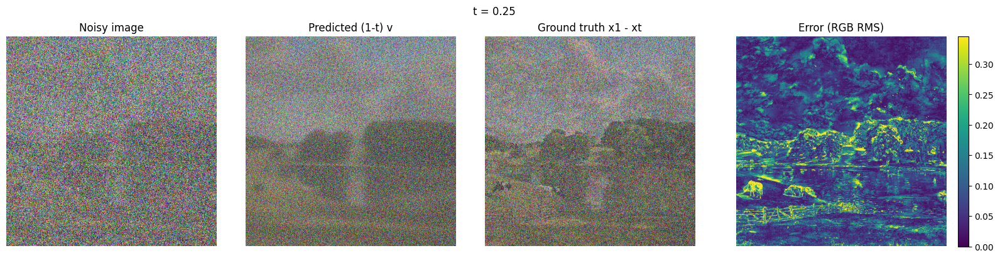

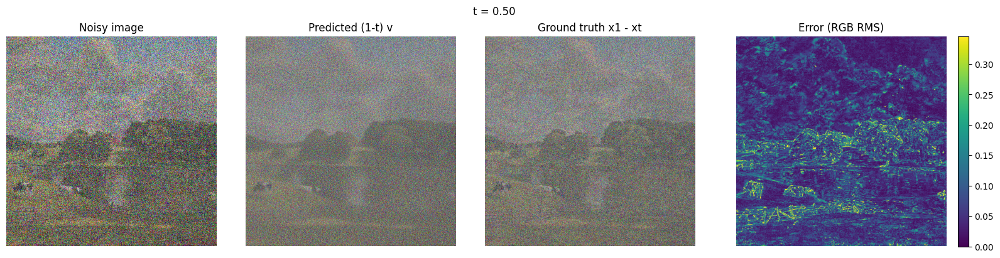

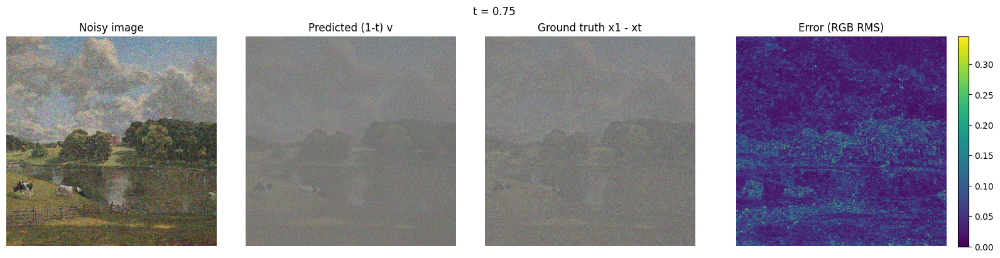

1.4 {'seconds': 8.8, 'network_evals': 3, 'seconds_per_eval': 2.941}


In [ ]:
# 1.4: predicted vs. ground-truth update, and the per-pixel RGB RMS error, on shared readable scales.
_t0, _c0 = time.perf_counter(), _calls["n"]
vel_path = OUT / 'velocity_raw.pt'
if vel_path.is_file():
    raw = torch.load(vel_path)
else:
    raw = {}
    for t in (0.25, 0.50, 0.75):
        x_t = interpolate(image, epsilon, t)
        p, g, e = velocity_diagnostics(x_t, t, image, epsilon, condition, predict_velocity)
        assert torch.allclose(g, image - x_t, atol=1e-5)
        raw[t] = {k: v.detach().cpu().half() for k, v in (('pred', p), ('gt', g), ('err', e))}
    torch.save(raw, vel_path)  # raw float16 tensors, so any display scale can be re-chosen offline
pred_gt = torch.cat([r[k].float().abs().flatten()[::11] for r in raw.values() for k in ('pred', 'gt')])
LIMIT = float(torch.quantile(pred_gt, 0.99))  # one symmetric scale for all six updates
EMAX = float(torch.quantile(torch.cat([r['err'].float().flatten()[::7] for r in raw.values()]), 0.99))
metrics['velocity'] = {
    'signed_limit_p99': LIMIT, 'error_vmax_p99': EMAX,
    'signed_limit_max': float(max(r[k].float().abs().max() for r in raw.values() for k in ('pred', 'gt'))),
    'error_max': float(max(r['err'].float().max() for r in raw.values())),
    'mean_rms': {f'{t:.2f}': float(r['err'].float().mean()) for t, r in raw.items()},
    'mean_abs_gt': {f'{t:.2f}': float(r['gt'].float().abs().mean()) for t, r in raw.items()}}


def srgb(u):
    return (0.5 + u.float()[0].permute(1, 2, 0) / (2 * LIMIT)).clamp(0, 1).numpy()


for t, r in raw.items():
    plt.imsave(OUT / 'img' / f'vel_pred_{t:.2f}.png', srgb(r['pred']))
    plt.imsave(OUT / 'img' / f'vel_gt_{t:.2f}.png', srgb(r['gt']))
    plt.imsave(OUT / 'img' / f'vel_err_{t:.2f}.png', r['err'].float()[0].numpy(), vmin=0, vmax=EMAX, cmap='viridis')
    save(f'vel_noisy_{t:.2f}', interpolate(image, epsilon, t))
    fig, ax = plt.subplots(1, 4, figsize=(16, 4), layout='constrained')
    fig.suptitle(f't = {t:.2f}')
    ax[0].imshow(to_pil(interpolate(image, epsilon, t)))
    ax[1].imshow(srgb(r['pred']))
    ax[2].imshow(srgb(r['gt']))
    im = ax[3].imshow(r['err'].float()[0].numpy(), vmin=0, vmax=EMAX, cmap='viridis')
    fig.colorbar(im, ax=ax[3], fraction=.046)
    for a, s in zip(ax, ('Noisy image', 'Predicted (1-t) v', 'Ground truth x1 - xt', 'Error (RGB RMS)')):
        a.set_title(s)
        a.axis('off')
    fig.savefig(OUT / 'panels' / f'velocity_{t:.2f}.png', dpi=200)
    plt.show()
    plt.close(fig)
fig = plt.figure(figsize=(6, 1.0))
cax = fig.add_axes([0.04, 0.55, 0.92, 0.3])
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, EMAX), cmap='viridis'), cax=cax,
             orientation='horizontal', label='RGB RMS error')
fig.savefig(OUT / 'img' / 'vel_colorbar.png', dpi=160, facecolor='white')
plt.close(fig)
record('1.4', _t0, _c0)


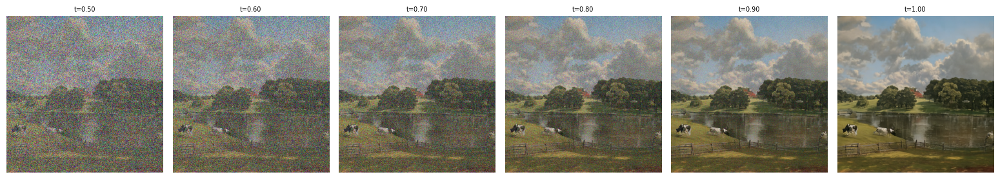

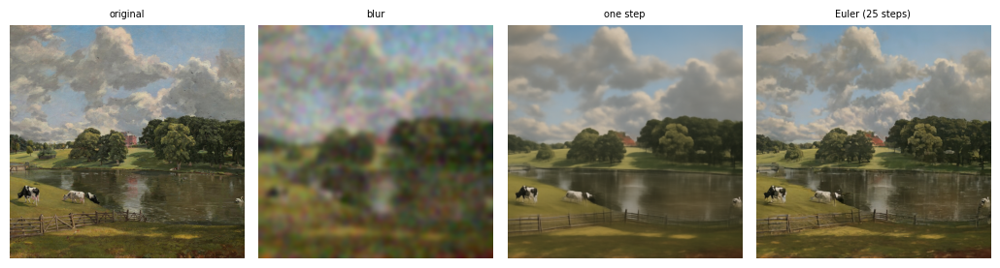

1.5 {'seconds': 15.6, 'network_evals': 25, 'seconds_per_eval': 0.622}


In [ ]:
# 1.5: Euler sampling. Checked against a constant velocity field first, then run from t = 0.5.
calls = []
def constant_v(x, t):
    calls.append(t)
    return torch.ones_like(x)
toy = torch.zeros(1, 3, 4, 4, device=device)
for start, step, expected in [(0, .02, 50), (.5, .02, 25), (.93, .02, 4)]:
    calls.clear()
    end, states = euler_sample(toy, start, step, constant_v)
    assert len(calls) == expected and states[-1][0] == 1
    assert torch.allclose(end, torch.full_like(toy, 1 - start), atol=1e-6)
metrics['euler_checks'] = '50 full steps, 25 half steps, shortened final step: passed'
_t0, _c0 = time.perf_counter(), _calls["n"]
if not (OUT / 'img' / 'sec1_traj_1.00.png').is_file():
    final, states = euler_sample(noisy[0.50], 0.50, H, lambda x, t: predict_velocity(x, t, condition))
    for t, x in states:
        save(f'sec1_traj_{t:.2f}', x)
final = img('sec1_traj_1.00')
metrics['sec1']['euler_mse'] = float(((final - image) ** 2).mean())
metrics['sec1']['blur_mse_0.50'] = float(((blurred[0.50] - image) ** 2).mean())
show({f't={t:.2f}': img(f'sec1_traj_{t:.2f}') for t in (0.5, 0.6, 0.7, 0.8, 0.9, 1.0)}, columns=6)
show({'original': image, 'blur': blurred[0.50], 'one step': one_step[0.50], 'Euler (25 steps)': final})
record('1.5', _t0, _c0)


## 1.6 Generating from Noise and 2.1 Classifier-Free Guidance


/content/cs180-hw3/vendor/PixNerd/src/models/transformer/pixnerd_t2i.py:95: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at /pytorch/aten/src/ATen/native/Copy.cpp:308.)
  pos = pos[None, :, :].to(device=device, dtype=dtype)


1.6+2.1 {'seconds': 416.7, 'network_evals': 750, 'seconds_per_eval': 0.556}
1.6+2.1 {'seconds': 416.7, 'network_evals': 750, 'seconds_per_eval': 0.556}
1.6+2.1 {'seconds': 416.7, 'network_evals': 750, 'seconds_per_eval': 0.556}
1.6+2.1 {'seconds': 416.7, 'network_evals': 750, 'seconds_per_eval': 0.556}
1.6+2.1 {'seconds': 416.7, 'network_evals': 750, 'seconds_per_eval': 0.556}


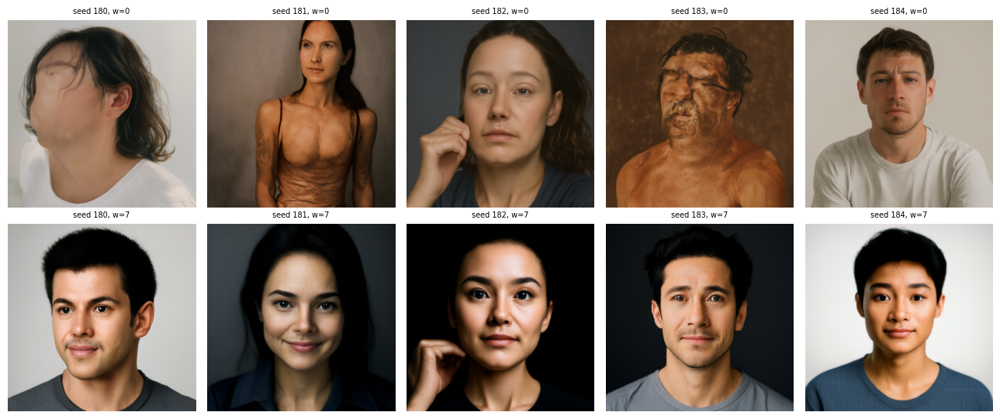

In [ ]:
# 1.6: sampling from pure noise, conditional, no guidance. 2.1: the same five noises with CFG (w = 7).
xc = noise(SEED)
assert torch.equal(cfg_velocity(xc, .5, condition, 0, predict_velocity, null_condition), predict_velocity(xc, .5, condition))
metrics['cfg_zero_check'] = True
_t0, _c0 = time.perf_counter(), _calls["n"]
for i in range(5):
    cached(f'conditional_{i}', lambda: euler_sample(noise(SEED + i), 0, H, lambda x, t: predict_velocity(x, t, condition))[0])
    cached(f'cfg_{i}', lambda: euler_sample(noise(SEED + i), 0, H, guided)[0])
    record('1.6+2.1', _t0, _c0)
show({**{f'seed {SEED + i}, w=0': img(f'conditional_{i}') for i in range(5)},
      **{f'seed {SEED + i}, w=7': img(f'cfg_{i}') for i in range(5)}}, columns=5)


## 3.1 Image-to-Image Editing


3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}


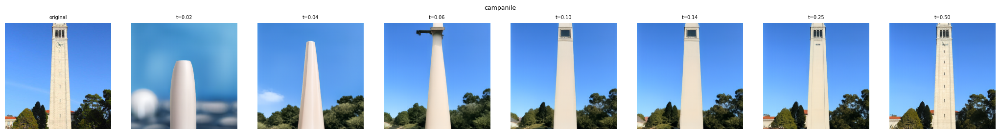

3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}


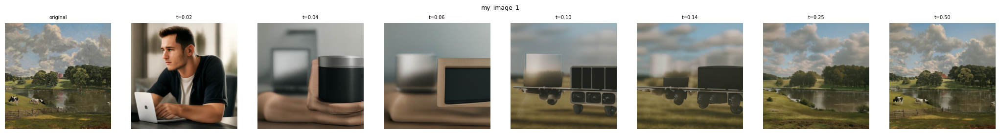

3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}


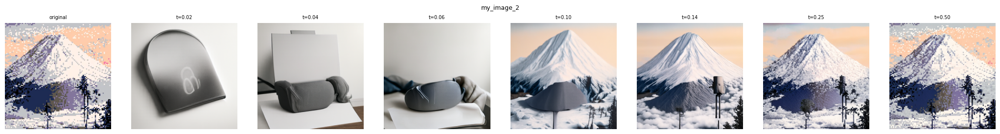

3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}


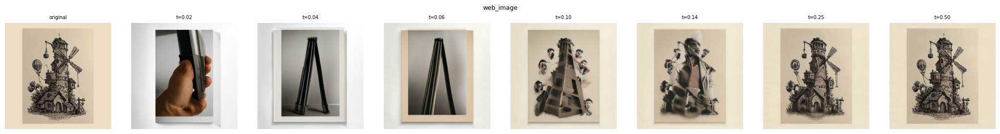

3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}


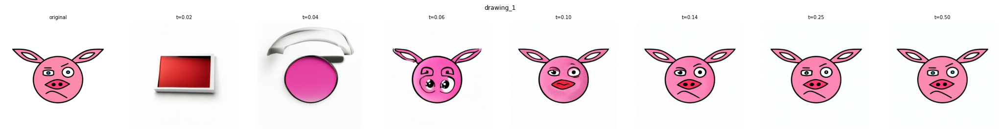

3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}
3.1 {'seconds': 1968.1, 'network_evals': 3540, 'seconds_per_eval': 0.556}


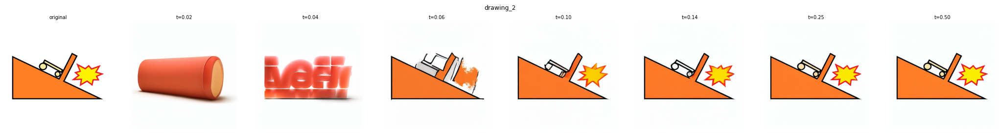

In [ ]:
# 3.1: SDEdit-style editing, prompt "a high quality photo", seven start times. Campanile + my two images,
# a web image and my two drawings (drawings composited on white).
STARTS = [0.02, 0.04, 0.06, 0.10, 0.14, 0.25, 0.50]
campanile = preprocess(ROOT / 'assets/campanile.jpg').to(device)
EDIT_INPUTS = {'campanile': campanile, 'my_image_1': load('wivenhoe_park.png'), 'my_image_2': load('pixel_fuji.png'),
               'web_image': load('fantasy_architecture.png'), 'drawing_1': load('pig_drawing.png'),
               'drawing_2': load('kart_drawing.png')}
_t0, _c0 = time.perf_counter(), _calls["n"]
for name, y in EDIT_INPUTS.items():
    save(f'edit_{name}_original', y)
    for t in STARTS:
        cached(f'edit_{name}_t_{t:.2f}', lambda: edit(y, noise(SEED), t, condition, predict_velocity, w=W, step_size=H))
        record('3.1', _t0, _c0)
    show({'original': y, **{f't={t:.2f}': img(f'edit_{name}_t_{t:.2f}') for t in STARTS}}, columns=8, title=name)


## 3.2 Text-Guided Image Editing


3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}


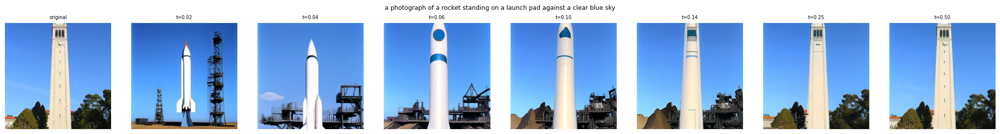

3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}


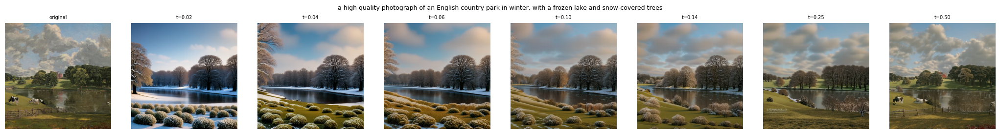

3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}
3.2 {'seconds': 984.0, 'network_evals': 1770, 'seconds_per_eval': 0.556}


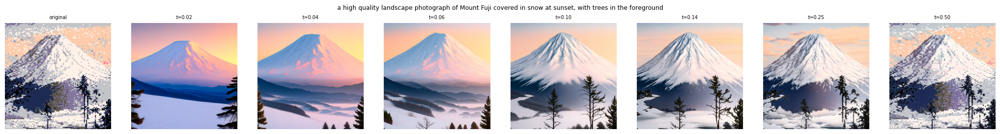

In [ ]:
# 3.2: text-guided editing, same seven start times.
EDIT_PROMPTS = {
    'campanile': 'a photograph of a rocket standing on a launch pad against a clear blue sky',
    'my_image_1': 'a high quality photograph of an English country park in winter, with a frozen lake and snow-covered trees',
    'my_image_2': 'a high quality landscape photograph of Mount Fuji covered in snow at sunset, with trees in the foreground',
}
metrics['text_edit_prompts'] = EDIT_PROMPTS
_t0, _c0 = time.perf_counter(), _calls["n"]
for name, prompt in EDIT_PROMPTS.items():
    y, c = EDIT_INPUTS[name], model.encode(prompt)
    for t in STARTS:
        cached(f'text_edit_{name}_t_{t:.2f}', lambda: edit(y, noise(SEED), t, c, predict_velocity, w=W, step_size=H))
        record('3.2', _t0, _c0)
    show({'original': y, **{f't={t:.2f}': img(f'text_edit_{name}_t_{t:.2f}') for t in STARTS}}, columns=8, title=prompt)


## 3.3 Visual Anagrams


3.3 {'seconds': 222.0, 'network_evals': 400, 'seconds_per_eval': 0.555}


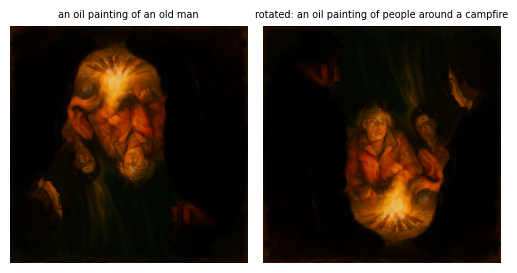

3.3 {'seconds': 222.0, 'network_evals': 400, 'seconds_per_eval': 0.555}


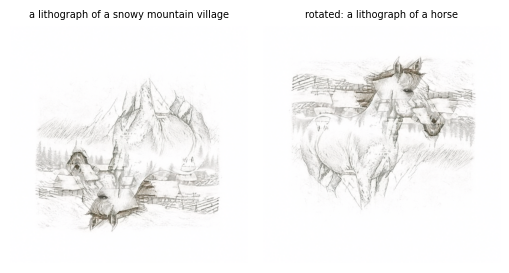

In [ ]:
# 3.3: visual anagrams (upright prompt a, upside-down prompt b).
ANAGRAMS = [('an oil painting of an old man', 'an oil painting of people around a campfire'),
            ('a lithograph of a snowy mountain village', 'a lithograph of a horse')]
assert torch.equal(rotate180(rotate180(image)), image)
metrics['anagram_prompts'] = ANAGRAMS
_t0, _c0 = time.perf_counter(), _calls["n"]
for i, (a, b) in enumerate(ANAGRAMS):
    ca, cb = model.encode(a), model.encode(b)
    x = cached(f'anagram_{i}', lambda: visual_anagrams(noise(SEED + i), ca, cb, predict_velocity, w=W, step_size=H))
    save(f'anagram_{i}_rotated', rotate180(x))
    record('3.3', _t0, _c0)
    show({a: x, 'rotated: ' + b: rotate180(x)}, columns=2)


## 3.4 Hybrid Images


3.4 {'seconds': 772.2, 'network_evals': 1200, 'seconds_per_eval': 0.644}


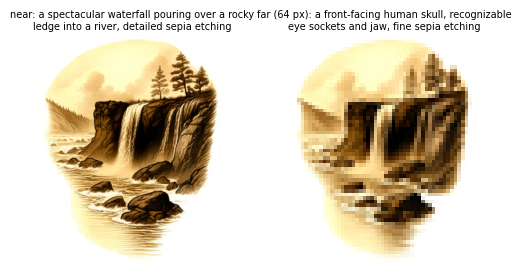

3.4 {'seconds': 772.2, 'network_evals': 1200, 'seconds_per_eval': 0.644}


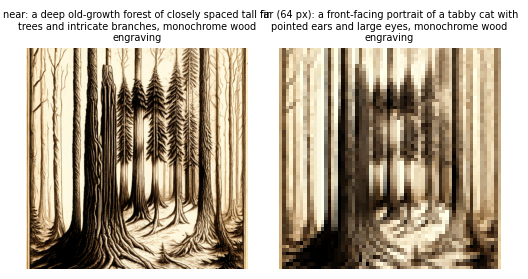

3.4 {'seconds': 772.2, 'network_evals': 1200, 'seconds_per_eval': 0.644}


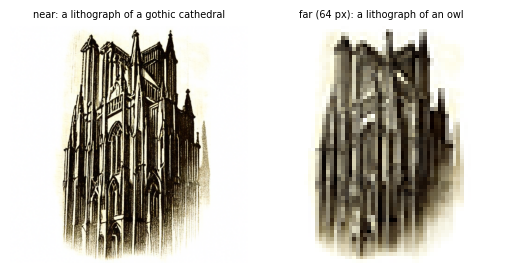

3.4 {'seconds': 772.2, 'network_evals': 1200, 'seconds_per_eval': 0.644}


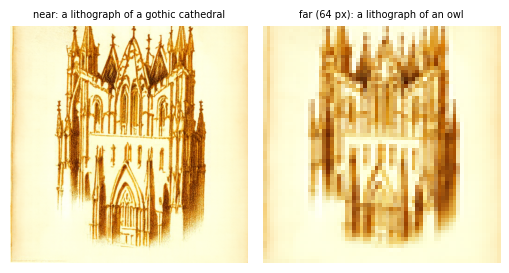

3.4 {'seconds': 772.2, 'network_evals': 1200, 'seconds_per_eval': 0.644}


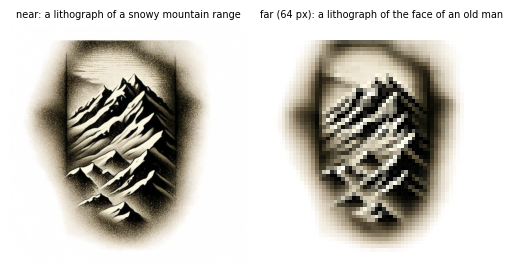

3.4 {'seconds': 772.2, 'network_evals': 1200, 'seconds_per_eval': 0.644}


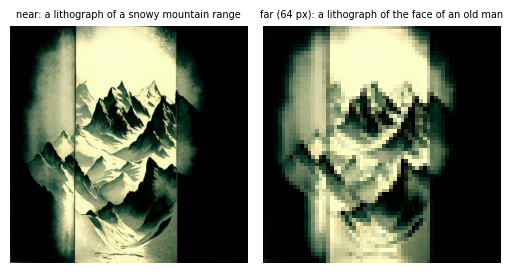

In [ ]:
# 3.4: hybrid images (low frequencies from the "far" prompt, high from the "near" prompt). The first is the
# course's skull / waterfall pair; the others are candidates for a second hybrid. All are saved and shown.
HYBRIDS = [('skull_waterfall', 921, 'a front-facing human skull, recognizable eye sockets and jaw, fine sepia etching',
            'a spectacular waterfall pouring over a rocky ledge into a river, detailed sepia etching'),
           ('cat_forest', 923, 'a front-facing portrait of a tabby cat with pointed ears and large eyes, monochrome wood engraving',
            'a deep old-growth forest of closely spaced tall fir trees and intricate branches, monochrome wood engraving'),
           ('owl_cathedral_180', 180, 'a lithograph of an owl', 'a lithograph of a gothic cathedral'),
           ('owl_cathedral_181', 181, 'a lithograph of an owl', 'a lithograph of a gothic cathedral'),
           ('oldman_mountains_180', 180, 'a lithograph of the face of an old man', 'a lithograph of a snowy mountain range'),
           ('oldman_mountains_181', 181, 'a lithograph of the face of an old man', 'a lithograph of a snowy mountain range')]
metrics['hybrids'] = {}
_t0, _c0 = time.perf_counter(), _calls["n"]
for name, s, far, near in HYBRIDS:
    x = cached('hybrid_' + name, lambda: make_hybrids(noise(s), model.encode(far), model.encode(near),
                                                      predict_velocity, w=W, step_size=H))
    small = to_pil(x).resize((64, 64), Image.Resampling.LANCZOS)
    small.save(OUT / 'img' / f'hybrid_{name}_small.png')
    metrics['hybrids'][name] = {'seed': s, 'far': far, 'near': near, 'lowpass_sigma': 16}
    record('3.4', _t0, _c0)
    show({'near: ' + near: x, 'far (64 px): ' + far: small}, columns=2)


## Bells & Whistles (required for CS280A)


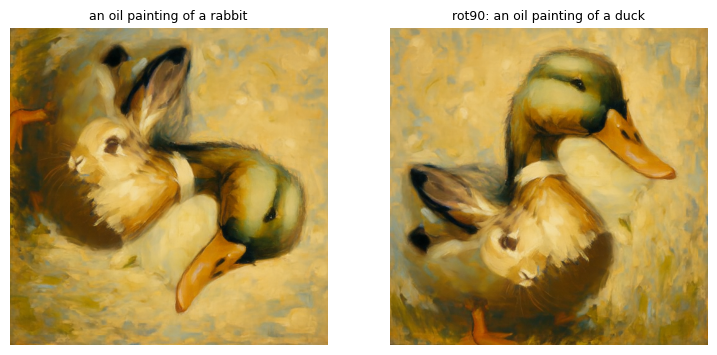

B&W_anagrams {'seconds': 890.8, 'network_evals': 1600, 'seconds_per_eval': 0.557}


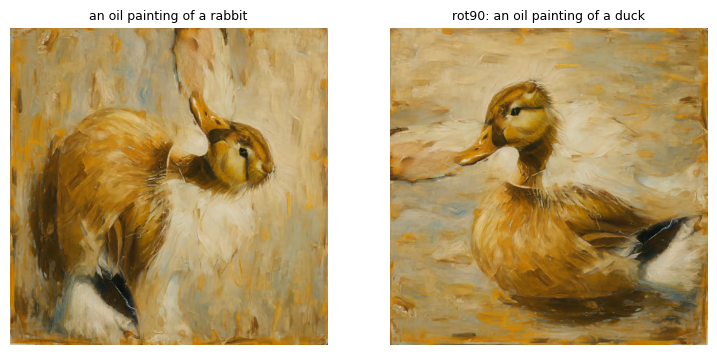

B&W_anagrams {'seconds': 890.8, 'network_evals': 1600, 'seconds_per_eval': 0.557}


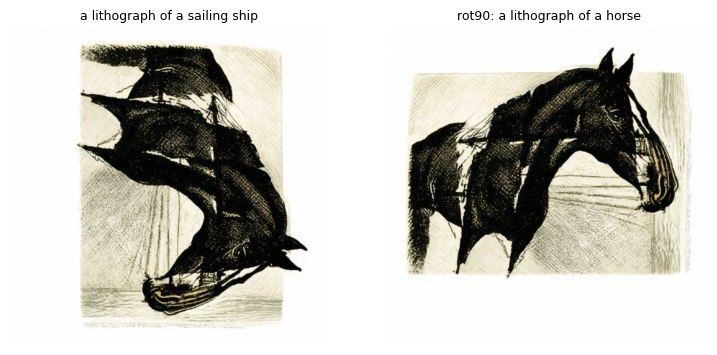

B&W_anagrams {'seconds': 890.8, 'network_evals': 1600, 'seconds_per_eval': 0.557}


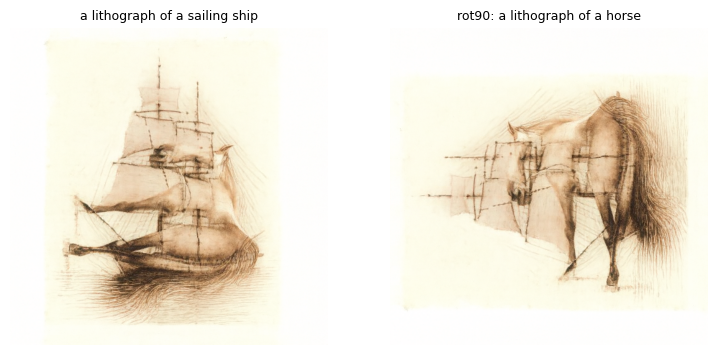

B&W_anagrams {'seconds': 890.8, 'network_evals': 1600, 'seconds_per_eval': 0.557}


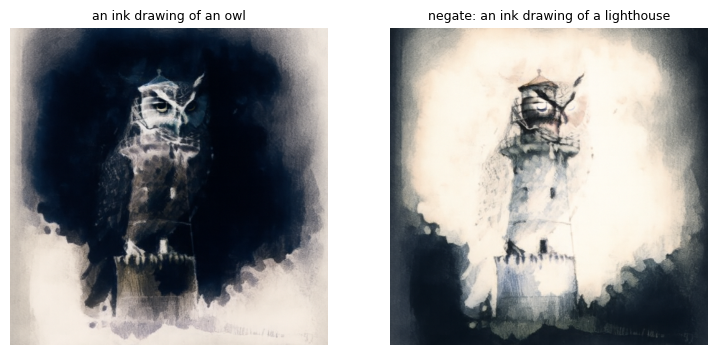

B&W_anagrams {'seconds': 890.8, 'network_evals': 1600, 'seconds_per_eval': 0.557}


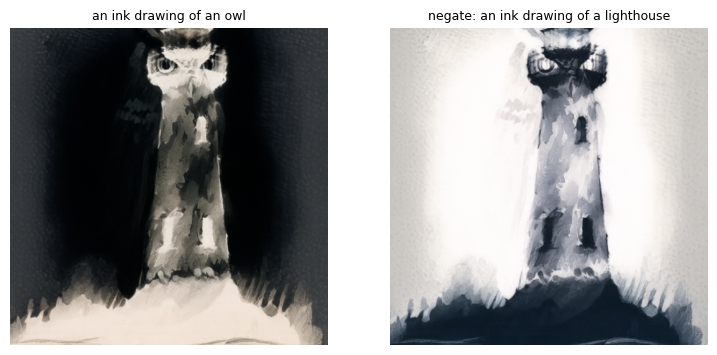

B&W_anagrams {'seconds': 890.8, 'network_evals': 1600, 'seconds_per_eval': 0.557}


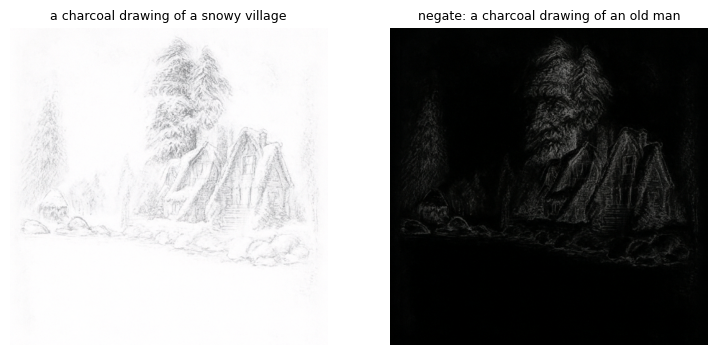

B&W_anagrams {'seconds': 890.8, 'network_evals': 1600, 'seconds_per_eval': 0.557}


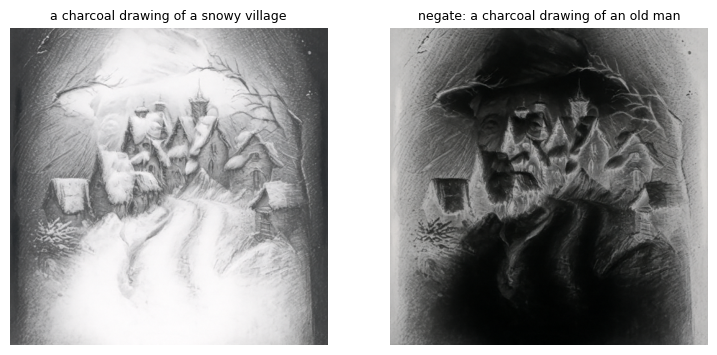

B&W_anagrams {'seconds': 890.8, 'network_evals': 1600, 'seconds_per_eval': 0.557}


In [ ]:
# CS280A bells & whistles: visual anagrams with two more orthogonal pixel transforms (Geng et al., Visual Anagrams).
# Same rule as Section 3.3: v = (v_a(x) + T^-1 v_b(T x)) / 2, valid because T is an orthogonal linear map on pixels,
# so T x of Gaussian noise is still Gaussian noise. PixNerd works directly on pixels, so no latent decoder breaks this.
def rot90(x):        # view seen after turning the image a quarter turn counter-clockwise
    return torch.rot90(x, 1, (-2, -1))
def rot90_inv(x):
    return torch.rot90(x, -1, (-2, -1))
def negate(x):       # color negative: in [-1, 1] pixel space this is x -> -x, its own inverse
    return -x

def anagram_T(noise, ca, cb, T, T_inv, w=W, step_size=H):
    def velocity(x, t):
        v_a = cfg_velocity(x, t, ca, w, predict_velocity, null_condition)
        v_b = T_inv(cfg_velocity(T(x), t, cb, w, predict_velocity, null_condition))
        return (v_a + v_b) / 2
    return euler_sample(noise, 0, step_size, velocity)[0]

x_check = noise(1)
assert torch.equal(rot90_inv(rot90(x_check)), x_check) and torch.equal(negate(negate(x_check)), x_check)
ANAGRAMS_280 = {
    'rot90': (rot90, rot90_inv, [('an oil painting of a rabbit', 'an oil painting of a duck'),
                                 ('a lithograph of a sailing ship', 'a lithograph of a horse')]),
    'negate': (negate, negate, [('an ink drawing of an owl', 'an ink drawing of a lighthouse'),
                                ('a charcoal drawing of a snowy village', 'a charcoal drawing of an old man')]),
}
_t0, _c0 = time.perf_counter(), _calls["n"]
metrics['anagrams_280'] = {}
for tname, (T, T_inv, pairs) in ANAGRAMS_280.items():
    for i, (a, b) in enumerate(pairs):
        ca, cb = model.encode(a), model.encode(b)
        for s in (SEED, SEED + 1):
            name = f'anagram_{tname}_{i}_s{s}'
            x = cached(name, lambda: anagram_T(noise(s), ca, cb, T, T_inv))
            save(name + '_view', T(x))
            metrics['anagrams_280'][name] = {'transform': tname, 'identity_prompt': a, 'transformed_prompt': b, 'seed': s}
            fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
            ax[0].imshow(to_pil(x)); ax[0].set_title(a, fontsize=9)
            ax[1].imshow(to_pil(T(x))); ax[1].set_title(f'{tname}: {b}', fontsize=9)
            for k in ax: k.axis('off')
            plt.show(); plt.close(fig)
            record('B&W_anagrams', _t0, _c0)


In [ ]:
# CS280A bells & whistles: course logo by text-guided image-to-image translation (Section 3.2's edit()).
# Inputs: my own hand-drawn sketch of the logo, and a cleaned-up Berkeley blue/gold version of it (tall condensed letters
# whose heights follow the circle), drawn in code by tools/make_logo.py.
STYLE = 'a clean minimalist emblem logo, bold gold letters CS180 filling a Berkeley blue circle with a thin gold ring, flat vector graphic'
LOGOS = [('sketch', 'logo_sketch.png', STYLE),
         ('cs180', 'logo_cs180.png', STYLE),
         ('cs180_pin', 'logo_cs180.png', 'a glossy navy blue and gold enamel pin badge of a circular CS180 logo, product photo on a white table')]
LOGO_STARTS = [0.06, 0.14, 0.25]
_t0, _c0 = time.perf_counter(), _calls["n"]
metrics['logos'] = {}
for name, file, prompt in LOGOS:
    y = load(file); c = model.encode(prompt)
    save(f'logo_{name}_original', y)
    for t in LOGO_STARTS:
        cached(f'logo_{name}_t_{t:.2f}', lambda: edit(y, noise(SEED), t, c, predict_velocity, w=W, step_size=H))
        record('B&W_logo', _t0, _c0)
    metrics['logos'][name] = {'input': file, 'prompt': prompt, 'starts': LOGO_STARTS}
    _mp.write_text(json.dumps(metrics, indent=2))


B&W_logo {'seconds': 427.5, 'network_evals': 768, 'seconds_per_eval': 0.557}
B&W_logo {'seconds': 427.5, 'network_evals': 768, 'seconds_per_eval': 0.557}
B&W_logo {'seconds': 427.5, 'network_evals': 768, 'seconds_per_eval': 0.557}
B&W_logo {'seconds': 427.5, 'network_evals': 768, 'seconds_per_eval': 0.557}
B&W_logo {'seconds': 427.5, 'network_evals': 768, 'seconds_per_eval': 0.557}
B&W_logo {'seconds': 427.5, 'network_evals': 768, 'seconds_per_eval': 0.557}
B&W_logo {'seconds': 427.5, 'network_evals': 768, 'seconds_per_eval': 0.557}
B&W_logo {'seconds': 427.5, 'network_evals': 768, 'seconds_per_eval': 0.557}
B&W_logo {'seconds': 427.5, 'network_evals': 768, 'seconds_per_eval': 0.557}


## Own ideas (optional for all students)


In [ ]:
# Own idea: how few Euler steps can we get away with? Same seed and prompt, CFG w = 7, h = 1/n.
_t0, _c0 = time.perf_counter(), _calls["n"]
metrics['step_sweep'] = {'steps': [5, 10, 25, 50], 'seed': SEED, 'prompt': 'a high quality photo', 'cfg_w': W}
for n in (5, 10, 25, 50):
    cached(f'steps_{n}', lambda: euler_sample(noise(SEED), 0, 1 / n, lambda x, t: cfg_velocity(x, t, condition, W, predict_velocity, null_condition))[0])
    record('own_step_sweep', _t0, _c0)


own_step_sweep {'seconds': 100.2, 'network_evals': 180, 'seconds_per_eval': 0.557}
own_step_sweep {'seconds': 100.2, 'network_evals': 180, 'seconds_per_eval': 0.557}
own_step_sweep {'seconds': 100.2, 'network_evals': 180, 'seconds_per_eval': 0.557}
own_step_sweep {'seconds': 100.2, 'network_evals': 180, 'seconds_per_eval': 0.557}


In [ ]:
# Own idea: inpainting with a flow model: generate only inside a mask, and after every Euler step reset
# the known pixels to the exact point they would occupy on the straight path at that time, x_t = (1-t) eps + t y.
# Three uses: removing an object, replacing it with a different one, and SWAPPING two objects (cut-and-paste swap,
# then the masked regions are regenerated from t_start = 0.3 so lighting and edges blend).
def inpaint(y, mask, cond, seed, t_start=0.0, w=W, step_size=H):
    eps = noise(seed)
    m = mask.to(device)
    def velocity(x, t):
        return cfg_velocity(x, t, cond, w, predict_velocity, null_condition)
    x = interpolate(y, eps, t_start)
    n = math.ceil(round((1 - t_start) / step_size, 9))
    for k in range(n):
        t = t_start + k * step_size
        h = min(step_size, 1 - t)
        t_next = 1.0 if k == n - 1 else t + h
        x = x + h * velocity(x, t)
        x = m * x + (1 - m) * interpolate(y, eps, t_next)      # known pixels follow their exact path
    return x

def box_mask(boxes, pad=0):
    m = torch.zeros(1, 1, 512, 512)
    for x0, y0, x1, y1 in boxes:
        m[..., max(0, y0 - pad):y1 + pad, max(0, x0 - pad):x1 + pad] = 1
    return m

wiv = image
COWS, HOUSE = (112, 352, 196, 396), (230, 226, 290, 270)     # x0, y0, x1, y1 in the 512 x 512 Wivenhoe Park crop
def swapped(img, a, b):
    """Paste box a's content into box b and vice versa (each resized to the other's box)."""
    out = img.clone()
    pa = img[..., a[1]:a[3], a[0]:a[2]]; pb = img[..., b[1]:b[3], b[0]:b[2]]
    out[..., b[1]:b[3], b[0]:b[2]] = F.interpolate(pa, size=(b[3] - b[1], b[2] - b[0]), mode='bilinear', align_corners=False)
    out[..., a[1]:a[3], a[0]:a[2]] = F.interpolate(pb, size=(a[3] - a[1], a[2] - a[0]), mode='bilinear', align_corners=False)
    return out

INPAINT = []
if campanile is not None:
    INPAINT.append(('remove_campanile', campanile, box_mask([(204, 0, 332, 512)]),
                    'a photo of a clear blue sky above green trees and red-roofed buildings', 0.0))
INPAINT += [('replace_cows', wiv, box_mask([(0, 336, 200, 404)]),
             'an oil painting by John Constable of a park by a lake, with two brown horses grazing on the grass', 0.0),
            ('swap_cows_house', swapped(wiv, COWS, HOUSE), box_mask([COWS, HOUSE], pad=10),
             'an oil painting by John Constable of an English country park with a lake', 0.3)]
_t0, _c0 = time.perf_counter(), _calls["n"]
metrics['inpainting'] = {}
for name, y, m, prompt, t0_ in INPAINT:
    save(f'inpaint_{name}_input', y)
    save(f'inpaint_{name}_mask', (m.repeat(1, 3, 1, 1) * 2 - 1).to(device))
    c = model.encode(prompt)
    for s in (SEED, SEED + 1):
        cached(f'inpaint_{name}_s{s}', lambda: inpaint(y, m, c, s, t_start=t0_))
        record('own_inpainting', _t0, _c0)
    metrics['inpainting'][name] = {'prompt': prompt, 't_start': t0_, 'seeds': [SEED, SEED + 1]}
_mp.write_text(json.dumps(metrics, indent=2))


own_inpainting {'seconds': 299.8, 'network_evals': 540, 'seconds_per_eval': 0.555}
own_inpainting {'seconds': 299.8, 'network_evals': 540, 'seconds_per_eval': 0.555}
own_inpainting {'seconds': 299.8, 'network_evals': 540, 'seconds_per_eval': 0.555}
own_inpainting {'seconds': 299.8, 'network_evals': 540, 'seconds_per_eval': 0.555}
own_inpainting {'seconds': 299.8, 'network_evals': 540, 'seconds_per_eval': 0.555}
own_inpainting {'seconds': 299.8, 'network_evals': 540, 'seconds_per_eval': 0.555}


11043

In [ ]:
# Own idea: multi-view rotation anagrams: average the velocities of N views,
# v(x) = 1/N sum_k T_k^-1 v_k(T_k x), each view with its own prompt.
# 4 views: exact 90-degree turns (a pixel permutation). 6 views: 60-degree turns cannot be done exactly on a square
# pixel grid, so I rotate only the inscribed disc, ring by ring: the pixels of each 1-px ring are sorted by angle and
# cyclically shifted by one sixth of the ring (the <=5 leftover pixels of a ring stay put, scattered around it). That is an exact
# permutation, so it is orthogonal and keeps Gaussian noise Gaussian, and applying it six times is the identity.
def ring_rotation(size=512, k=6):
    yy, xx = torch.meshgrid(torch.arange(size), torch.arange(size), indexing='ij')
    dx, dy = xx + 0.5 - size / 2, yy + 0.5 - size / 2
    r, ang = torch.sqrt(dx ** 2 + dy ** 2), torch.atan2(dy, dx)
    g = torch.arange(size * size)                     # T(x).flat[j] = x.flat[g[j]]
    ring = r.floor().long().flatten(); angf = ang.flatten()
    for rr in range(size // 2):
        idx = torch.nonzero(ring == rr).flatten()
        idx = idx[torch.argsort(angf[idx])]
        n, L = len(idx), len(idx) % k
        if n - L == 0: continue
        fixed = (torch.arange(L) * n // max(L, 1) + 7 * rr) % n          # scatter the <=5 fixed pixels around the ring
        keep = torch.ones(n, dtype=torch.bool); keep[fixed] = False
        ids = idx[keep]; m = len(ids); s = m // k
        g[ids[(torch.arange(m) + s) % m]] = ids
    ginv = torch.empty_like(g); ginv[g] = torch.arange(size * size)
    return g, ginv

_g6, _g6inv = (t.to(device) for t in ring_rotation())
def rot60(x, times=1):
    for _ in range(times % 6):
        x = x.flatten(-2)[..., _g6].view_as(x)
    return x
def rot60_inv(x, times=1):
    for _ in range(times % 6):
        x = x.flatten(-2)[..., _g6inv].view_as(x)
    return x
_xc = noise(3)
assert torch.equal(rot60(_xc, 6), _xc) and torch.equal(rot60_inv(rot60(_xc, 2), 2), _xc)

def multiview_anagram(seed, conds, T, T_inv, w=W, step_size=H):
    N = len(conds)
    def velocity(x, t):
        return sum(T_inv(cfg_velocity(T(x, k), t, c, w, predict_velocity, null_condition), k)
                   for k, c in enumerate(conds)) / N
    return euler_sample(noise(seed), 0, step_size, velocity)[0]

rot4 = lambda x, k: torch.rot90(x, k, (-2, -1))
rot4_inv = lambda x, k: torch.rot90(x, -k, (-2, -1))
VIEWS4 = ['a lithograph of a horse', 'a lithograph of a sailing ship', 'a lithograph of an old man', 'a lithograph of a rabbit']
VIEWS6 = VIEWS4 + ['a lithograph of an owl', 'a lithograph of a castle']
metrics['multiview'] = {'four_way': {'prompts': VIEWS4, 'seeds': [SEED, SEED + 1]},
                        'six_way': {'prompts': VIEWS6, 'seeds': [SEED], 'transform': 'ring-permutation 60-degree rotation of the inscribed disc'}}
_t0, _c0 = time.perf_counter(), _calls["n"]
c4 = [model.encode(p) for p in VIEWS4]
for s in (SEED, SEED + 1):
    x = cached(f'rot4_s{s}', lambda: multiview_anagram(s, c4, rot4, rot4_inv))
    for k in range(4): save(f'rot4_s{s}_view{k}', rot4(x, k))
    record('own_four_way', _t0, _c0)
_t0, _c0 = time.perf_counter(), _calls["n"]
c6 = [model.encode(p) for p in VIEWS6]
x = cached(f'rot6_s{SEED}', lambda: multiview_anagram(SEED, c6, rot60, rot60_inv))
for k in range(6): save(f'rot6_s{SEED}_view{k}', rot60(x, k))
record('own_six_way', _t0, _c0)


own_four_way {'seconds': 443.8, 'network_evals': 800, 'seconds_per_eval': 0.555}
own_four_way {'seconds': 443.8, 'network_evals': 800, 'seconds_per_eval': 0.555}
own_six_way {'seconds': 333.6, 'network_evals': 600, 'seconds_per_eval': 0.556}


own_make_it_real {'seconds': 50.3, 'network_evals': 90, 'seconds_per_eval': 0.559}
own_make_it_real {'seconds': 92.4, 'network_evals': 166, 'seconds_per_eval': 0.557}


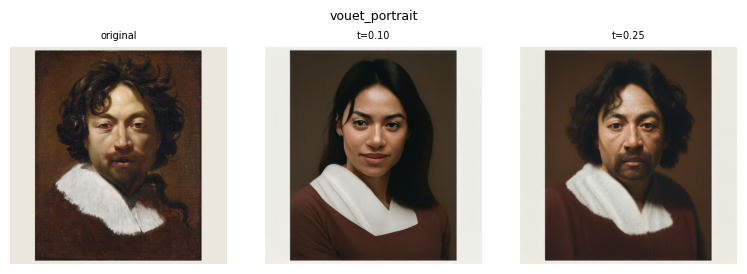

own_make_it_real {'seconds': 142.7, 'network_evals': 256, 'seconds_per_eval': 0.558}
own_make_it_real {'seconds': 184.7, 'network_evals': 332, 'seconds_per_eval': 0.556}


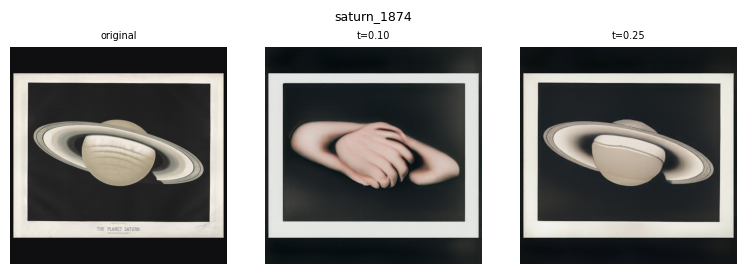

own_make_it_real {'seconds': 235.2, 'network_evals': 422, 'seconds_per_eval': 0.557}
own_make_it_real {'seconds': 277.2, 'network_evals': 498, 'seconds_per_eval': 0.557}


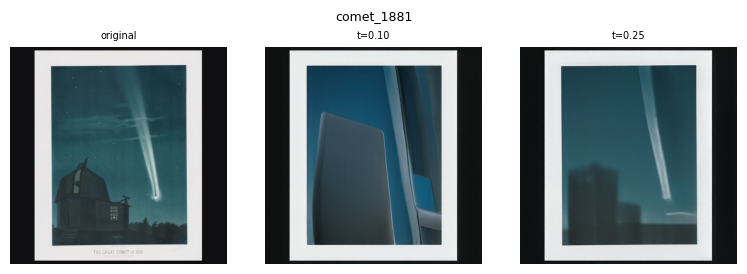

own_make_it_real {'seconds': 327.6, 'network_evals': 588, 'seconds_per_eval': 0.557}
own_make_it_real {'seconds': 370.0, 'network_evals': 664, 'seconds_per_eval': 0.557}


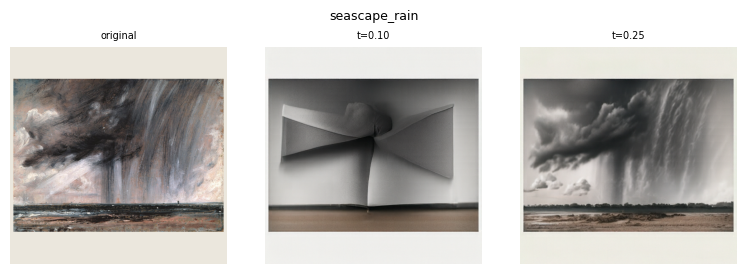

own_make_it_real {'seconds': 420.2, 'network_evals': 754, 'seconds_per_eval': 0.557}
own_make_it_real {'seconds': 462.5, 'network_evals': 830, 'seconds_per_eval': 0.557}


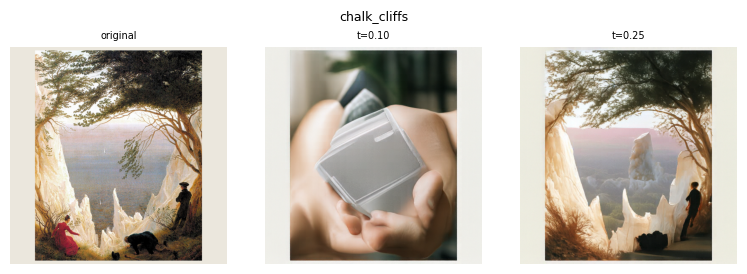

own_make_it_real {'seconds': 512.7, 'network_evals': 920, 'seconds_per_eval': 0.557}
own_make_it_real {'seconds': 554.9, 'network_evals': 996, 'seconds_per_eval': 0.557}


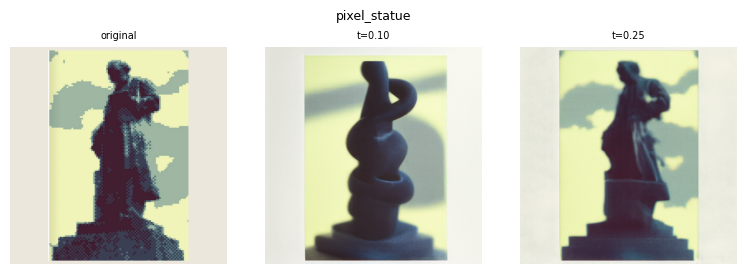

In [ ]:
# Own idea: "make it real" on paintings, astronomical prints and pixel art (Section 3.1's edit, generic prompt).
EXTRA = ['vouet_portrait', 'saturn_1874', 'comet_1881', 'seascape_rain', 'chalk_cliffs', 'pixel_statue']
EXTRA_STARTS = [0.10, 0.25]
_t0, _c0 = time.perf_counter(), _calls["n"]
for name in EXTRA:
    y = load(name + '.png')
    save(f'extra_{name}_original', y)
    for t in EXTRA_STARTS:
        cached(f'extra_{name}_t_{t:.2f}', lambda: edit(y, noise(SEED), t, condition, predict_velocity, w=W, step_size=H))
        record('own_make_it_real', _t0, _c0)
    show({'original': y, **{f't={t:.2f}': img(f'extra_{name}_t_{t:.2f}') for t in EXTRA_STARTS}}, columns=3, title=name)


## Save and download the results


In [ ]:
metrics['peak_memory_gib'] = torch.cuda.max_memory_allocated() / 2 ** 30
_mp.write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics['timing'], indent=1))
import shutil
_zip = shutil.make_archive(str(OUT.parent / 'cs180_proj3_parta_final'), 'zip', OUT)
print('Download:', _zip)
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(_zip)


{
 "1.1-1.3": {
  "seconds": 5.1,
  "network_evals": 3,
  "seconds_per_eval": 1.715
 },
 "1.4": {
  "seconds": 8.8,
  "network_evals": 3,
  "seconds_per_eval": 2.941
 },
 "1.5": {
  "seconds": 15.6,
  "network_evals": 25,
  "seconds_per_eval": 0.622
 },
 "1.6+2.1": {
  "seconds": 416.7,
  "network_evals": 750,
  "seconds_per_eval": 0.556
 },
 "3.1": {
  "seconds": 1968.1,
  "network_evals": 3540,
  "seconds_per_eval": 0.556
 },
 "3.2": {
  "seconds": 984.0,
  "network_evals": 1770,
  "seconds_per_eval": 0.556
 },
 "3.3": {
  "seconds": 222.0,
  "network_evals": 400,
  "seconds_per_eval": 0.555
 },
 "3.4": {
  "seconds": 772.2,
  "network_evals": 1200,
  "seconds_per_eval": 0.644
 },
 "B&W_anagrams": {
  "seconds": 890.8,
  "network_evals": 1600,
  "seconds_per_eval": 0.557
 },
 "B&W_logo": {
  "seconds": 427.5,
  "network_evals": 768,
  "seconds_per_eval": 0.557
 },
 "own_step_sweep": {
  "seconds": 100.2,
  "network_evals": 180,
  "seconds_per_eval": 0.557
 },
 "own_inpainting": {
  "

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Additional runs (same session)
Run after reviewing the results above. They add hybrid candidates (the second hybrid comes from here) and refine the
inpainting, the logo and the anagrams. Every new result is saved under a new name, so nothing above was overwritten,
and the cells re-zip the results folder at the end.


3.4_fresh {'seconds': 128.8, 'network_evals': 200, 'seconds_per_eval': 0.644}


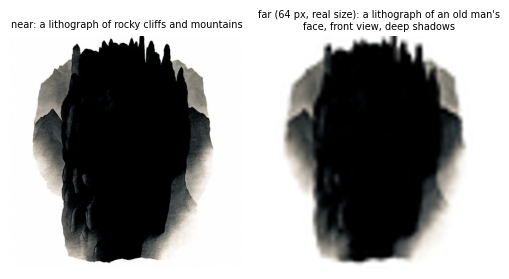

3.4_fresh {'seconds': 257.2, 'network_evals': 400, 'seconds_per_eval': 0.643}


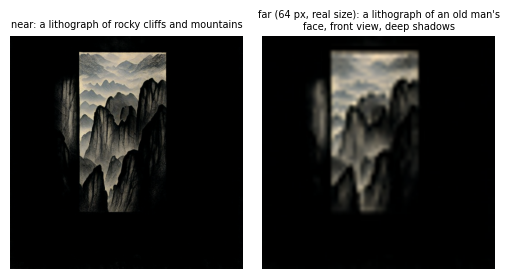

3.4_fresh {'seconds': 386.3, 'network_evals': 600, 'seconds_per_eval': 0.644}


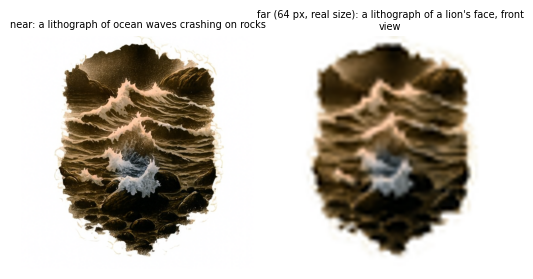

3.4_fresh {'seconds': 515.2, 'network_evals': 800, 'seconds_per_eval': 0.644}


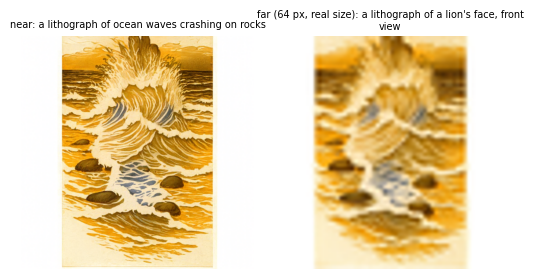

3.4_fresh {'seconds': 644.2, 'network_evals': 1000, 'seconds_per_eval': 0.644}


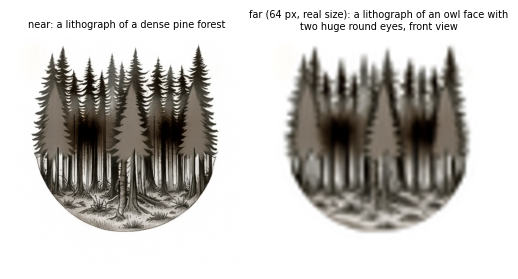

3.4_fresh {'seconds': 772.6, 'network_evals': 1200, 'seconds_per_eval': 0.644}


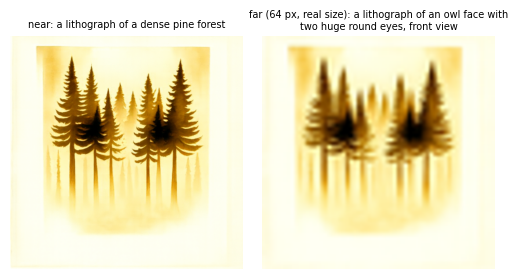

3.4_fresh {'seconds': 901.8, 'network_evals': 1400, 'seconds_per_eval': 0.644}


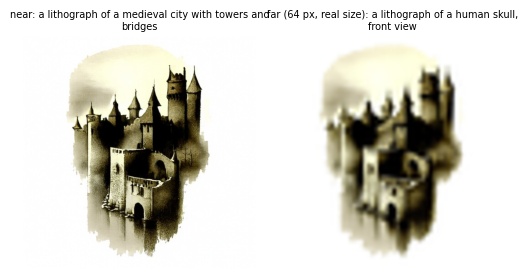

3.4_fresh {'seconds': 1031.1, 'network_evals': 1600, 'seconds_per_eval': 0.644}


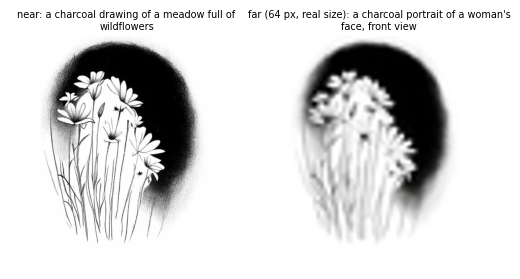

Re-zipped with the new hybrids: /content/drive/MyDrive/cs180_proj3_parta_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 3.4, more hybrid candidates: front-facing heads as the far subject. Only large dark shapes survive the
# sigma-16 low-pass, which is why the skull worked and the cat, owl and old man above did not.
FRESH = [('face_cliffs', 180, "a lithograph of an old man's face, front view, deep shadows", 'a lithograph of rocky cliffs and mountains'),
         ('face_cliffs', 181, "a lithograph of an old man's face, front view, deep shadows", 'a lithograph of rocky cliffs and mountains'),
         ('lion_waves', 180, "a lithograph of a lion's face, front view", 'a lithograph of ocean waves crashing on rocks'),
         ('lion_waves', 181, "a lithograph of a lion's face, front view", 'a lithograph of ocean waves crashing on rocks'),
         ('owlface_forest', 180, 'a lithograph of an owl face with two huge round eyes, front view', 'a lithograph of a dense pine forest'),
         ('owlface_forest', 181, 'a lithograph of an owl face with two huge round eyes, front view', 'a lithograph of a dense pine forest'),
         ('skull_city', 180, 'a lithograph of a human skull, front view', 'a lithograph of a medieval city with towers and bridges'),
         ('woman_flowers', 180, "a charcoal portrait of a woman's face, front view", 'a charcoal drawing of a meadow full of wildflowers')]
_t0, _c0 = time.perf_counter(), _calls["n"]
metrics.setdefault('hybrids', {})
for name, s, far, near in FRESH:
    key = f'{name}_{s}'
    x = cached('hybrid_' + key, lambda: make_hybrids(noise(s), model.encode(far), model.encode(near),
                                                     predict_velocity, w=W, step_size=H))
    small = to_pil(x).resize((64, 64), Image.Resampling.LANCZOS)
    small.save(OUT / 'img' / f'hybrid_{key}_small.png')
    metrics['hybrids'][key] = {'seed': s, 'far': far, 'near': near, 'lowpass_sigma': 16}
    record('3.4_fresh', _t0, _c0)
    # far view shown at its real 64 px size (no blocky enlargement), next to the full image
    show({'near: ' + near: x, 'far (64 px, real size): ' + far: to_pil(x).resize((64, 64), Image.Resampling.LANCZOS).resize((512, 512), Image.Resampling.BICUBIC)}, columns=2)
import shutil
_zip = shutil.make_archive(str(OUT.parent / 'cs180_proj3_parta_final'), 'zip', OUT)
print('Re-zipped with the new hybrids:', _zip)
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(_zip)

3.4_round2 {'seconds': 130.2, 'network_evals': 200, 'seconds_per_eval': 0.651}


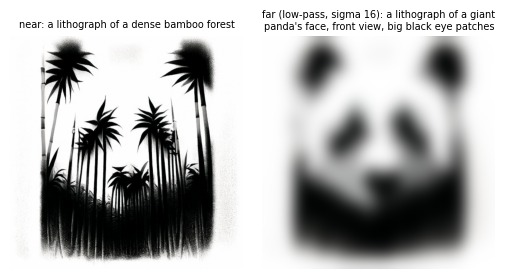

3.4_round2 {'seconds': 258.6, 'network_evals': 400, 'seconds_per_eval': 0.646}


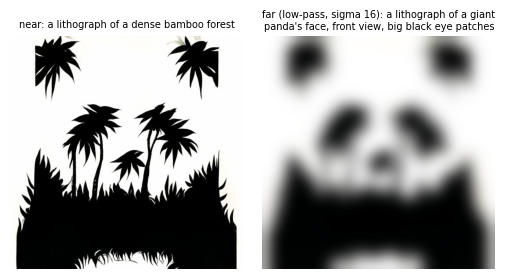

3.4_round2 {'seconds': 387.6, 'network_evals': 600, 'seconds_per_eval': 0.646}


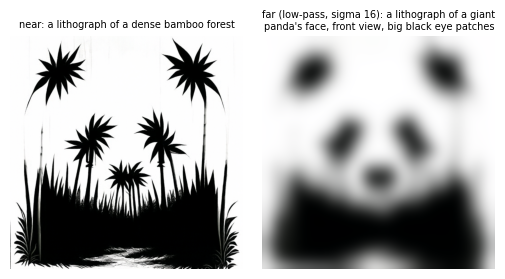

3.4_round2 {'seconds': 515.6, 'network_evals': 800, 'seconds_per_eval': 0.645}


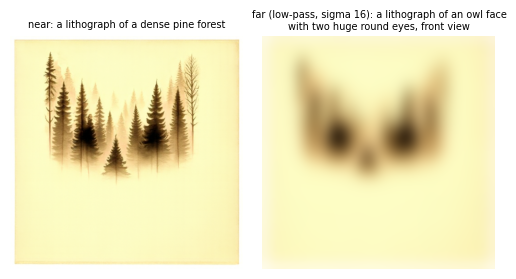

3.4_round2 {'seconds': 644.6, 'network_evals': 1000, 'seconds_per_eval': 0.645}


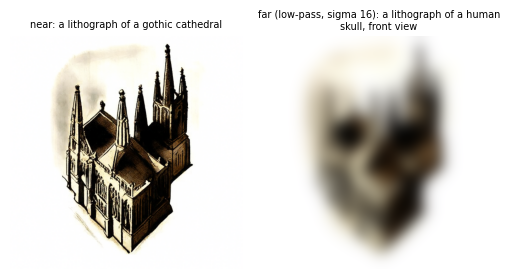

3.4_round2 {'seconds': 773.3, 'network_evals': 1200, 'seconds_per_eval': 0.644}


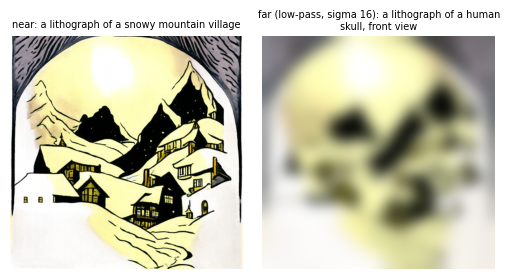

Re-zipped: /content/drive/MyDrive/cs180_proj3_parta_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 3.4, second round of hybrid candidates: far subjects with large dark features on a light field
# (a panda's eye patches, an owl's eyes, a skull's sockets). The panda / bamboo pair is the second hybrid.
ROUND2 = [('panda_bamboo', 180, "a lithograph of a giant panda's face, front view, big black eye patches", 'a lithograph of a dense bamboo forest'),
          ('panda_bamboo', 181, "a lithograph of a giant panda's face, front view, big black eye patches", 'a lithograph of a dense bamboo forest'),
          ('panda_bamboo', 182, "a lithograph of a giant panda's face, front view, big black eye patches", 'a lithograph of a dense bamboo forest'),
          ('owlface_forest', 182, 'a lithograph of an owl face with two huge round eyes, front view', 'a lithograph of a dense pine forest'),
          ('skull_cathedral', 180, 'a lithograph of a human skull, front view', 'a lithograph of a gothic cathedral'),
          ('skull_village', 181, 'a lithograph of a human skull, front view', 'a lithograph of a snowy mountain village')]
_t0, _c0 = time.perf_counter(), _calls["n"]
metrics.setdefault('hybrids', {})
for name, s, far, near in ROUND2:
    key = f'{name}_{s}'
    x = cached('hybrid_' + key, lambda: make_hybrids(noise(s), model.encode(far), model.encode(near),
                                                     predict_velocity, w=W, step_size=H))
    to_pil(x).resize((64, 64), Image.Resampling.LANCZOS).save(OUT / 'img' / f'hybrid_{key}_small.png')
    metrics['hybrids'][key] = {'seed': s, 'far': far, 'near': near, 'lowpass_sigma': 16}
    record('3.4_round2', _t0, _c0)
    # "far" preview = what survives the low-pass, i.e. what a distant viewer sees
    show({'near: ' + near: x, 'far (low-pass, sigma 16): ' + far: lowpass(x)}, columns=2)
import shutil
_zip = shutil.make_archive(str(OUT.parent / 'cs180_proj3_parta_final'), 'zip', OUT)
print('Re-zipped:', _zip)
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(_zip)

polish {'seconds': 86.8, 'network_evals': 150, 'seconds_per_eval': 0.579}
polish {'seconds': 170.2, 'network_evals': 300, 'seconds_per_eval': 0.567}
polish {'seconds': 198.2, 'network_evals': 350, 'seconds_per_eval': 0.566}
polish {'seconds': 226.0, 'network_evals': 400, 'seconds_per_eval': 0.565}
polish {'seconds': 248.1, 'network_evals': 440, 'seconds_per_eval': 0.564}
polish {'seconds': 270.2, 'network_evals': 480, 'seconds_per_eval': 0.563}
polish {'seconds': 324.9, 'network_evals': 578, 'seconds_per_eval': 0.562}
polish {'seconds': 378.5, 'network_evals': 674, 'seconds_per_eval': 0.562}
polish {'seconds': 433.1, 'network_evals': 772, 'seconds_per_eval': 0.561}
polish {'seconds': 486.4, 'network_evals': 868, 'seconds_per_eval': 0.56}
polish {'seconds': 539.8, 'network_evals': 964, 'seconds_per_eval': 0.56}
polish {'seconds': 592.9, 'network_evals': 1060, 'seconds_per_eval': 0.559}
polish {'seconds': 924.5, 'network_evals': 1660, 'seconds_per_eval': 0.557}


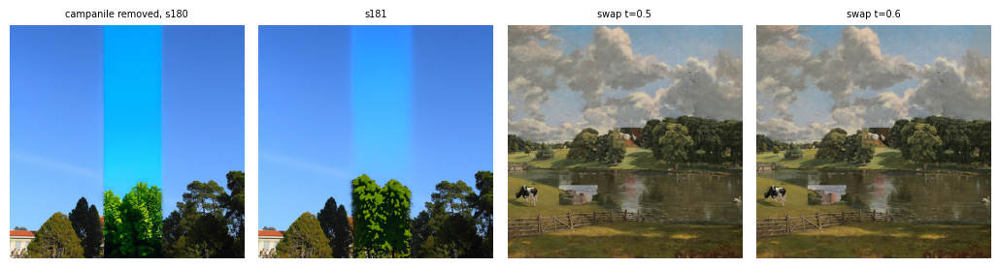

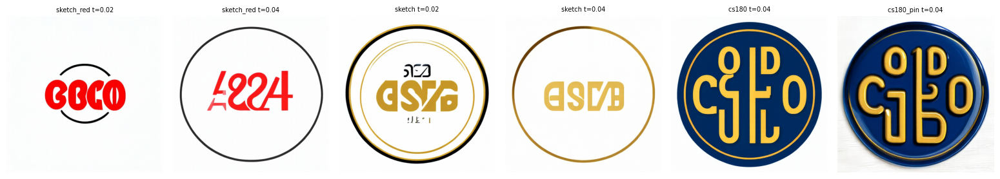

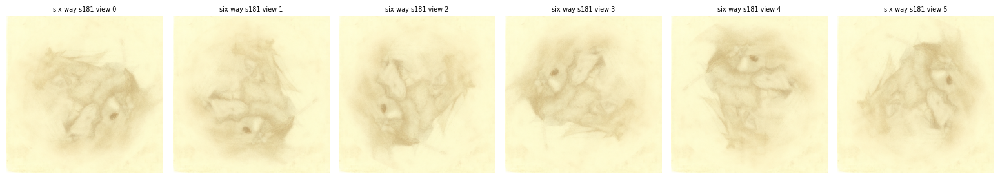

Re-zipped: /content/drive/MyDrive/cs180_proj3_parta_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Refinements after reviewing the results: inpainting with a feathered mask and a blending pass, the swap
# from later start times, earlier logo start times, and a second six-way seed.
import torch.nn.functional as F

def soft(mask, grow=12, feather=6):
    """Grow the mask by `grow` px and feather its edge, so new pixels blend into the old ones."""
    m = F.max_pool2d(mask, 2 * grow + 1, stride=1, padding=grow) if grow else mask
    k = 2 * math.ceil(3 * feather) + 1
    return gaussian_blur(m, [k, k], [feather, feather]).clamp(0, 1)

_t0, _c0 = time.perf_counter(), _calls["n"]
metrics.setdefault('polish', {})

# 1) Remove the Campanile again: feathered mask, then a harmonizing pass from t = 0.5 over a wider soft band,
#    so the new sky matches the old sky's color instead of leaving a bright strip.
prompt = 'a photo of a clear blue sky above green trees and red-roofed buildings'
c = model.encode(prompt)
m1 = soft(box_mask([(204, 0, 332, 512)]), grow=12, feather=6)
m2 = soft(box_mask([(204, 0, 332, 512)]), grow=40, feather=16)
save('inpaint_v2_remove_campanile_mask', (m1.repeat(1, 3, 1, 1) * 2 - 1).to(device))
for s in (SEED, SEED + 1):
    first = cached(f'inpaint_v2_remove_campanile_pass1_s{s}', lambda: inpaint(campanile, m1, c, s))
    cached(f'inpaint_v2_remove_campanile_s{s}', lambda: inpaint(first, m2, c, s, t_start=0.5))
    record('polish', _t0, _c0)
metrics['polish']['remove_campanile'] = {'prompt': prompt, 'pass1': 'grow 12 px, feather 6, t 0 -> 1',
                                         'pass2': 'grow 40 px, feather 16, t 0.5 -> 1'}

# 2) Swap again: from t = 0.3 the model "undid" the swap (house back on the hill, animals back on the bank).
#    Starting later keeps the swapped objects and only blends their edges.
prompt = 'an oil painting by John Constable of an English country park with a lake'
c = model.encode(prompt)
ms = soft(box_mask([COWS, HOUSE], pad=6), grow=0, feather=4)
for t0 in (0.5, 0.6):
    for s in (SEED, SEED + 1):
        cached(f'inpaint_v2_swap_t{t0:.2f}_s{s}', lambda: inpaint(swapped(wiv, COWS, HOUSE), ms, c, s, t_start=t0))
        record('polish', _t0, _c0)
metrics['polish']['swap'] = {'prompt': prompt, 't_start': [0.5, 0.6], 'mask': 'boxes + 6 px, feather 4'}

# 3) Logo: t = 0.14 / 0.25 barely changed the inputs, so add the earlier, stronger starts.
LOGO2 = [('sketch_red', 'logo_sketch.png', 'a clean professional minimalist logo, bold red letters CS180 neatly filling a thin black circle, white background, flat vector graphic', (0.02, 0.04)),
         ('sketch', 'logo_sketch.png', STYLE, (0.02, 0.04)),
         ('cs180', 'logo_cs180.png', STYLE, (0.04,)),
         ('cs180_pin', 'logo_cs180.png', 'a glossy navy blue and gold enamel pin badge of a circular CS180 logo, product photo on a white table', (0.04,))]
for name, file, p, starts in LOGO2:
    y, c = load(file), model.encode(p)
    save(f'logo_{name}_original', y)
    for t in starts:
        cached(f'logo_{name}_t_{t:.2f}', lambda: edit(y, noise(SEED), t, c, predict_velocity, w=W, step_size=H))
        record('polish', _t0, _c0)
    metrics['logos'][name] = {'input': file, 'prompt': p,
                              'starts': sorted(set(metrics['logos'].get(name, {}).get('starts', [])) | set(starts))}

# 4) A second seed for the six-way anagram.
x = cached('rot6_s181', lambda: multiview_anagram(SEED + 1, c6, rot60, rot60_inv))
for k in range(6):
    save(f'rot6_s181_view{k}', rot60(x, k))
metrics['multiview']['six_way']['seeds'] = [SEED, SEED + 1]
record('polish', _t0, _c0)
_mp.write_text(json.dumps(metrics, indent=2))

show({'campanile removed, s180': img('inpaint_v2_remove_campanile_s180'), 's181': img('inpaint_v2_remove_campanile_s181'),
      'swap t=0.5': img(f'inpaint_v2_swap_t0.50_s{SEED}'), 'swap t=0.6': img(f'inpaint_v2_swap_t0.60_s{SEED}')}, columns=4)
show({f'{n} t={t:.2f}': img(f'logo_{n}_t_{t:.2f}') for n, _, _, ts in LOGO2 for t in ts}, columns=6)
show({f'six-way s181 view {k}': img(f'rot6_s181_view{k}') for k in range(6)}, columns=6)
import shutil
_zip = shutil.make_archive(str(OUT.parent / 'cs180_proj3_parta_final'), 'zip', OUT)
print('Re-zipped:', _zip)
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(_zip)

The cell below was stopped by hand after its first six-way seed (hence the `KeyboardInterrupt`): that style
(bold woodcut, w = 10) collapsed into solid black shapes, so the remaining two seeds were not worth the GPU time.
Its inpainting results finished first and are kept.


polish2_inpaint {'seconds': 58.2, 'network_evals': 100, 'seconds_per_eval': 0.582}
polish2_inpaint {'seconds': 113.7, 'network_evals': 200, 'seconds_per_eval': 0.569}
polish2_inpaint {'seconds': 168.7, 'network_evals': 300, 'seconds_per_eval': 0.562}
polish2_inpaint {'seconds': 224.2, 'network_evals': 400, 'seconds_per_eval': 0.56}


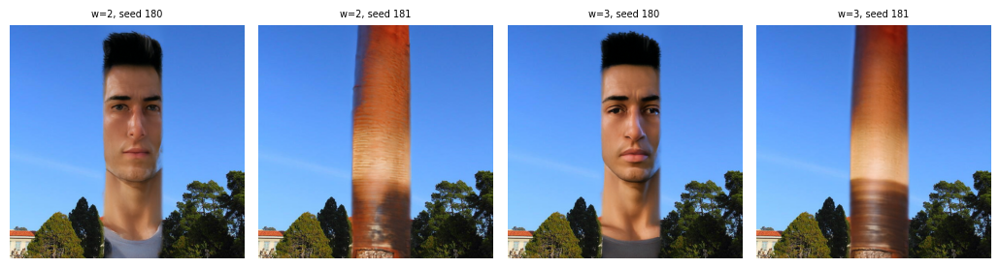

polish2_six_way {'seconds': 332.9, 'network_evals': 600, 'seconds_per_eval': 0.555}


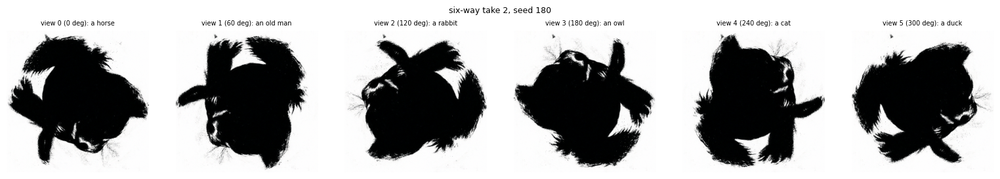

KeyboardInterrupt: 

In [ ]:
# Further refinements: inpainting with low guidance, and a second six-way style.

# 1) Campanile removal with LOWER guidance. At w = 7 the new sky came out a vivid cyan strip:
#    guidance pushes it toward an idealized "clear blue sky" and the model sees the real sky only through noisy pixels.
prompt = 'a high quality photo'
c = model.encode(prompt)
m1 = soft(box_mask([(204, 0, 332, 512)]), grow=12, feather=6)
_t0, _c0 = time.perf_counter(), _calls["n"]
for w_ in (2, 3):
    for s in (SEED, SEED + 1):
        cached(f'inpaint_v3_remove_campanile_w{w_}_s{s}', lambda: inpaint(campanile, m1, c, s, w=w_))
        record('polish2_inpaint', _t0, _c0)
metrics['polish']['remove_campanile_lowcfg'] = {'prompt': prompt, 'w': [2, 3], 'mask': 'grow 12 px, feather 6'}
show({f'w={w_}, seed {s}': img(f'inpaint_v3_remove_campanile_w{w_}_s{s}') for w_ in (2, 3) for s in (SEED, SEED + 1)}, columns=4)

# 2) Six-way anagram, take 2. Why the first one was faint: the six guided velocities are AVERAGED,
#    so each prompt's own push toward its subject is diluted to 1/6, and "lithograph" invites thin, pale lines.
#    Fixes: (a) w = 10 instead of 7 to give each view back some of its push; (b) a bold woodcut style with thick
#    black lines and high contrast, shared by all six views; (c) six compact subjects that read from a blob
#    (heads and animals) in place of the ship and castle, which never appeared.
STYLE6 = 'a bold black and white woodcut print of {}, thick black lines, high contrast'
SUBJECTS6 = ['a horse', 'an old man', 'a rabbit', 'an owl', 'a cat', 'a duck']
VIEWS6B = [STYLE6.format(s) for s in SUBJECTS6]
W6 = 10
c6b = [model.encode(p) for p in VIEWS6B]
_t0, _c0 = time.perf_counter(), _calls["n"]
for s in (SEED, SEED + 1, SEED + 2):
    x = cached(f'rot6b_s{s}', lambda: multiview_anagram(s, c6b, rot60, rot60_inv, w=W6))
    for k in range(6):
        save(f'rot6b_s{s}_view{k}', rot60(x, k))
    record('polish2_six_way', _t0, _c0)
    show({f'view {k} ({60 * k} deg): {SUBJECTS6[k]}': rot60(x, k) for k in range(6)}, columns=6, title=f'six-way take 2, seed {s}')
metrics['multiview']['six_way_b'] = {'prompts': VIEWS6B, 'seeds': [SEED, SEED + 1, SEED + 2], 'cfg_w': W6,
                                     'transform': 'ring-permutation 60-degree rotation of the inscribed disc'}
_mp.write_text(json.dumps(metrics, indent=2))

import shutil
_zip = shutil.make_archive(str(OUT.parent / 'cs180_proj3_parta_final'), 'zip', OUT)
print('Re-zipped:', _zip)
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(_zip)

fix {'seconds': 96.9, 'network_evals': 200, 'seconds_per_eval': 0.484}


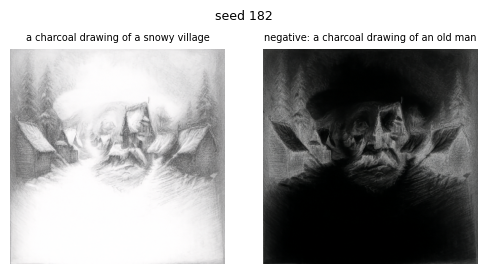

fix {'seconds': 194.4, 'network_evals': 400, 'seconds_per_eval': 0.486}


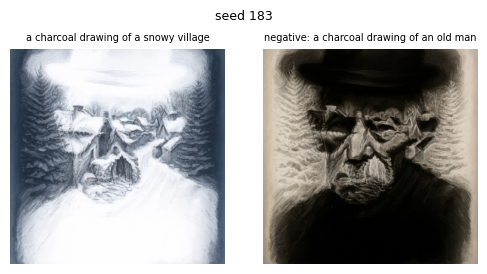

fix {'seconds': 291.6, 'network_evals': 600, 'seconds_per_eval': 0.486}


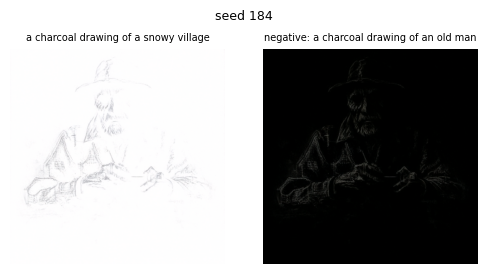

fix {'seconds': 336.5, 'network_evals': 692, 'seconds_per_eval': 0.486}
fix {'seconds': 380.4, 'network_evals': 782, 'seconds_per_eval': 0.486}


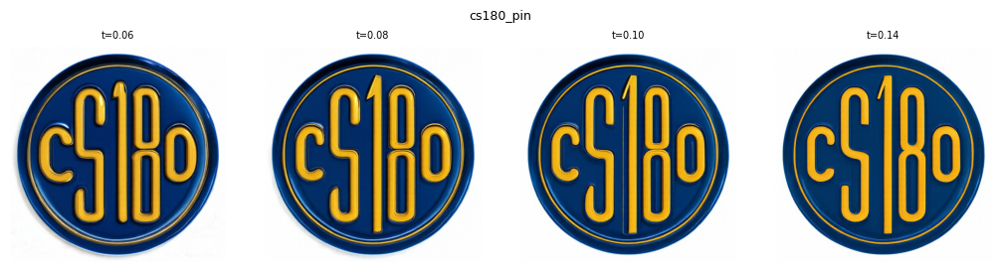

fix {'seconds': 425.7, 'network_evals': 874, 'seconds_per_eval': 0.487}
fix {'seconds': 469.6, 'network_evals': 964, 'seconds_per_eval': 0.487}


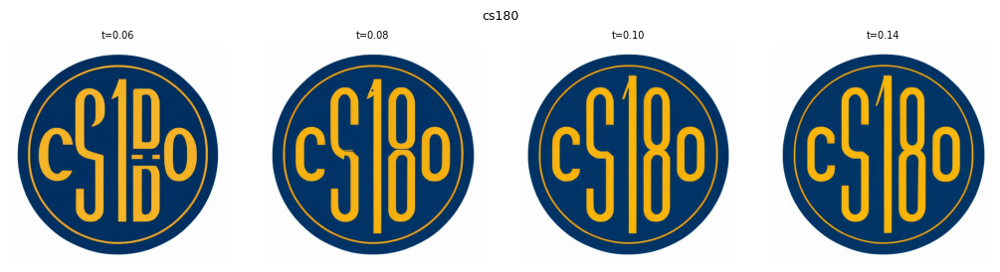

fix {'seconds': 514.8, 'network_evals': 1056, 'seconds_per_eval': 0.487}
fix {'seconds': 558.6, 'network_evals': 1146, 'seconds_per_eval': 0.487}


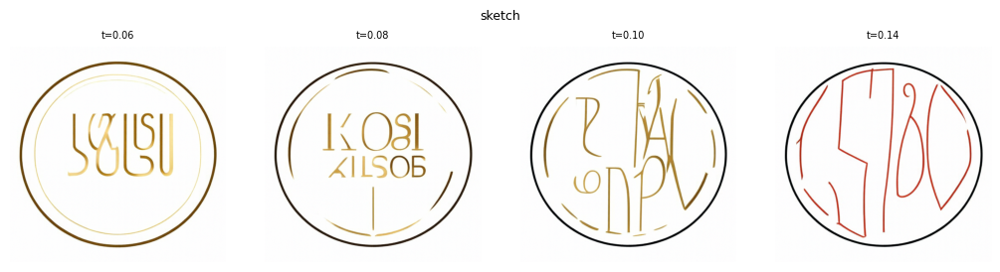

fix {'seconds': 685.7, 'network_evals': 1406, 'seconds_per_eval': 0.488}
fix {'seconds': 811.6, 'network_evals': 1666, 'seconds_per_eval': 0.487}
fix {'seconds': 937.8, 'network_evals': 1926, 'seconds_per_eval': 0.487}


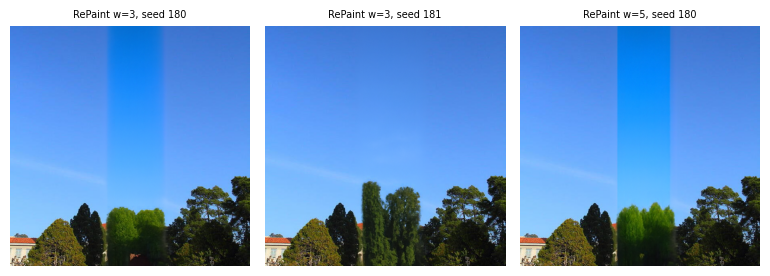

fix {'seconds': 1230.2, 'network_evals': 2526, 'seconds_per_eval': 0.487}


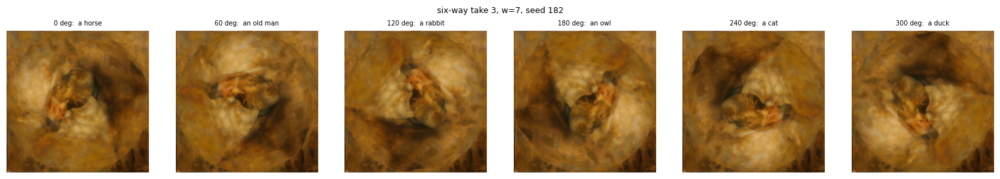

fix {'seconds': 1522.8, 'network_evals': 3126, 'seconds_per_eval': 0.487}


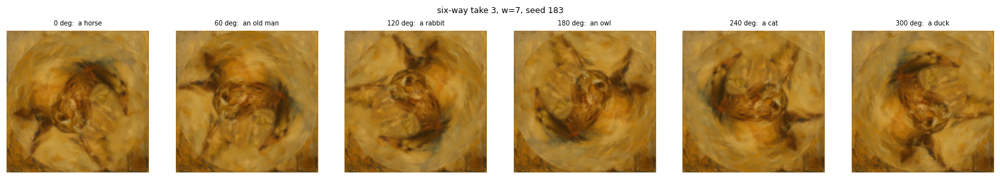

fix {'seconds': 1815.3, 'network_evals': 3726, 'seconds_per_eval': 0.487}


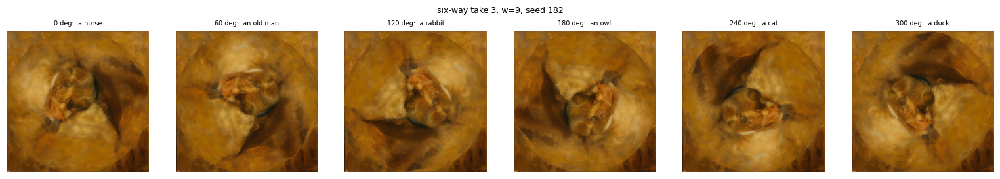

Re-zipped: /content/drive/MyDrive/cs180_proj3_parta_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Final refinements: more seeds for the color-negative village / old man, logo start times between 0.06 and
# 0.14, RePaint-style resampling for the Campanile removal, and a third six-way style.
import torch.nn.functional as F

def soft(mask, grow=12, feather=6):
    m = F.max_pool2d(mask, 2 * grow + 1, stride=1, padding=grow) if grow else mask
    k = 2 * math.ceil(3 * feather) + 1
    return gaussian_blur(m, [k, k], [feather, feather]).clamp(0, 1)

_t0, _c0 = time.perf_counter(), _calls["n"]
metrics.setdefault('fix', {})

# 1) Color-negative anagram, village -> old man: three more seeds.
a, b = 'a charcoal drawing of a snowy village', 'a charcoal drawing of an old man'
ca, cb = model.encode(a), model.encode(b)
for s in (SEED + 2, SEED + 3, SEED + 4):
    x = cached(f'anagram_negate_1_s{s}', lambda: anagram_T(noise(s), ca, cb, negate, negate))
    save(f'anagram_negate_1_s{s}_view', negate(x))
    record('fix', _t0, _c0)
    show({a: x, 'negative: ' + b: negate(x)}, columns=2, title=f'seed {s}')
metrics['fix']['negate_village_oldman_seeds'] = [SEED + 2, SEED + 3, SEED + 4]

# 2) Logo sweet spot: t = 0.06 redesigns but garbles the letters, t = 0.14 changes almost nothing.
for name, file, p in (('cs180_pin', 'logo_cs180.png', LOGOS[2][2]), ('cs180', 'logo_cs180.png', STYLE),
                      ('sketch', 'logo_sketch.png', STYLE)):
    y, c = load(file), model.encode(p)
    for t in (0.08, 0.10):
        cached(f'logo_{name}_t_{t:.2f}', lambda: edit(y, noise(SEED), t, c, predict_velocity, w=W, step_size=H))
        record('fix', _t0, _c0)
    show({f't={t:.2f}': img(f'logo_{name}_t_{t:.2f}') for t in (0.06, 0.08, 0.10, 0.14)}, columns=4, title=name)
metrics['fix']['logo_extra_starts'] = [0.08, 0.10]

# 3) Campanile removal with RePaint-style resampling. Plain "reset the known pixels" inpainting never lets
#    the generated strip adapt to its surroundings: it is decided from mostly-noise context early on and keeps its
#    too-bright color. Here every 5-step segment is run, re-noised back to its start (exactly onto the straight path's
#    noise level: x_t1 = (t1/t2) x_t2 + sqrt((1-t1)^2 - (t1(1-t2)/t2)^2) * fresh noise), and run again, 3 times,
#    so the masked area keeps re-harmonizing with the known pixels. Moderate guidance and a descriptive prompt.
def inpaint_repaint(y, mask, cond, seed, w, h=H, jump=5, resample=3):
    eps = noise(seed)
    m = mask.to(device)
    g = torch.Generator().manual_seed(seed + 999)
    n = round(1 / h)
    x = eps.clone()
    k = 0
    while k < n:
        end = min(k + jump, n)
        passes = 1 if k == 0 or end == n else resample
        for r in range(passes):
            for i in range(k, end):
                t = i * h
                x = x + h * cfg_velocity(x, t, cond, w, predict_velocity, null_condition)
                x = m * x + (1 - m) * interpolate(y, eps, (i + 1) * h)
            if r < passes - 1:
                t1, t2 = k * h, end * h
                sig = math.sqrt(max((1 - t1) ** 2 - (t1 * (1 - t2) / t2) ** 2, 0.0))
                x = (t1 / t2) * x + sig * torch.randn(x.shape, generator=g).to(device)
                x = m * x + (1 - m) * interpolate(y, eps, t1)
        k = end
    return x

prompt = 'a photo of an empty blue sky above green trees and red-roofed buildings, no tower'
c = model.encode(prompt)
mr = soft(box_mask([(204, 0, 332, 512)]), grow=12, feather=6)
for w_, s in ((3, SEED), (3, SEED + 1), (5, SEED)):
    cached(f'inpaint_v4_repaint_w{w_}_s{s}', lambda: inpaint_repaint(campanile, mr, c, s, w=w_))
    record('fix', _t0, _c0)
show({f'RePaint w={w_}, seed {s}': img(f'inpaint_v4_repaint_w{w_}_s{s}')
      for w_, s in ((3, SEED), (3, SEED + 1), (5, SEED))}, columns=3)
metrics['fix']['repaint'] = {'prompt': prompt, 'jump_steps': 5, 'resample': 3, 'runs': [[3, SEED], [3, SEED + 1], [5, SEED]]}

# 4) Six-way, take 3. Take 1 (lithograph) was faint, take 2 (woodcut, w = 10) collapsed into solid black.
#    Oil painting gives mid-tones and full shapes; the six subjects are the compact ones that showed up before.
VIEWS6C = [f'an oil painting of {s}' for s in ('a horse', 'an old man', 'a rabbit', 'an owl', 'a cat', 'a duck')]
c6c = [model.encode(p) for p in VIEWS6C]
for w_, s in ((7, SEED + 2), (7, SEED + 3), (9, SEED + 2)):
    x = cached(f'rot6c_w{w_}_s{s}', lambda: multiview_anagram(s, c6c, rot60, rot60_inv, w=w_))
    for k in range(6):
        save(f'rot6c_w{w_}_s{s}_view{k}', rot60(x, k))
    record('fix', _t0, _c0)
    show({f'{60 * k} deg: {VIEWS6C[k][18:]}': rot60(x, k) for k in range(6)}, columns=6, title=f'six-way take 3, w={w_}, seed {s}')
metrics['multiview']['six_way_c'] = {'prompts': VIEWS6C, 'runs': [[7, SEED + 2], [7, SEED + 3], [9, SEED + 2]]}
_mp.write_text(json.dumps(metrics, indent=2))

import shutil
_zip = shutil.make_archive(str(OUT.parent / 'cs180_proj3_parta_final'), 'zip', OUT)
print('Re-zipped:', _zip)
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(_zip)